# Utah wildfire occurrence modeling

Adam Valentino · ML v1 publication 1.0.0

These development years informed model and calibration choices. The results describe observations held out from individual fits, rather than an independent final evaluation. Contemporary terrain is treated as a static historical proxy; historical as-issued terrain and climate availability is unverified.

This notebook displays saved development evidence. Keep it in the release folder. Open `index.html` for the full offline presentation.

In [1]:
from pathlib import Path
import json, runpy
from IPython.display import display, Image, HTML, Markdown
DATA_MODE = "snapshot"
assert DATA_MODE == "snapshot"
ROOT = Path.cwd()
assert (ROOT / "release.json").is_file(), "Open this notebook from the extracted release folder."
viewer = runpy.run_path(str(ROOT / "viewer.py"))
display(viewer["verify"](ROOT, active_notebook=True))

{'verified_files': 50,
 'version': '1.0.0',
 'notebook_check': 'source only during execution',
 'new_model_fits': 0,
 'new_predictions': 0}

In [2]:
display(Markdown((ROOT / "narrative.md").read_text(encoding="utf-8")))
maps = json.loads((ROOT / "data/map_descriptions.json").read_text(encoding="utf-8"))

# Utah wildfire occurrence modeling

This ML extension estimates the probability of at least one **recorded wildfire discovery within a county-clipped grid cell during a UTC calendar year**. It compares Random Forest and XGBoost using terrain and antecedent climate, then audits probability calibration, spatial validation, reporting coverage and the effect of unequal cell area. The frozen ML v1 recommendation uses **conservative XGBoost probabilities** and keeps **raw XGBoost as the ranking reference**.

The development experiment uses **2001-2021**. Its held-out annual maps cover **2013-2021** across Salt Lake, Utah and Washington counties. Earlier years support training and calibration. The sample contains 997 nominal 4 km cells clipped to the county footprint, including land outside mapped WUI. The estimated quantity is recorded occurrence within the cell, rather than a property's chance of burning, fire severity or hazard per square kilometre.

## Validation and model choice

These development years informed model and calibration choices. The results describe observations held out from individual fits, rather than an independent final evaluation. Contemporary terrain is treated as a static historical proxy; historical as-issued terrain and climate availability is unverified.

For each target year T, base training uses 2001 through T-3 and calibration uses T-2 and T-1. Five geographic folds use 20 km blocks with 4 km exclusion buffers. Median imputation is fitted only on permitted training rows. Across nine validation years, the comparison covers 8,588 eligible cell-years and 656 recorded-positive cell-years. A cell-year is one cell observed for one year; repeated cell-years are not independent locations.

The primary model combines 14 terrain and area predictors with six antecedent climate predictors. The climate reconstruction uses measurement windows before each January 1 cutoff and an assumed 60-day release lag; historical as-issued versions remain unverified. Known reviewed labels, including flagged zeros, remain in training and calibration. The held-out maps exclude 230 unknown-label cell-years and 155 flagged-zero cell-years. A further unknown-label development observation occurs before the mapped years.

Conservative XGBoost has mean annual Brier score **0.070814**, compared with **0.071353** for raw XGBoost and **0.071341** for sigmoid-calibrated Random Forest. Lower Brier scores indicate better probability accuracy. Its relative reduction in mean annual Brier score versus saved past-rate forecasts is about 1%, so the probability gain is modest. Raw XGBoost retains the higher annual-average top-decile recall, **18.09% versus 17.42%** for conservative probabilities. This is a development recommendation, without a claim of a statistically significant winner or operational readiness.

## What the area audit changes about interpretation

There are **754 effectively full 16 km² cells** and **243 clipped boundary cells**. A full cell is within 0.000001 km² of 16 km². Area was the largest individual contributor in the saved model interpretation. Full cells account for **75.0% of eligible cell-years but 98.0% of both raw and conservative top-decile selections**. These are pooled 2013-2021 shares: 846 of 863 selection slots, not counts of distinct locations.

Smaller cells also have lower recorded occurrence frequencies. Conservative probabilities average **3.22%** in clipped cell-years, versus **3.03% recorded occurrence**. Full-cell values are **10.04%** and **9.17%**. The pooled clipped result masks variation in the larger clipped cells:

| Original area in km² | Eligible cell-years | Mean conservative probability | Recorded occurrence | Raw top-decile slots |
| --- | ---: | ---: | ---: | ---: |
| Below 4 | 770 | 1.35% | 0.00% | 0 |
| 4 to below 8 | 372 | 2.40% | 1.34% | 0 |
| 8 to below 12 | 398 | 2.73% | 2.76% | 0 |
| 12 to below 16 clipped | 606 | 6.40% | 8.09% | 17 |
| Full 16 | 6,442 | 10.04% | 9.17% | 846 |

The 12-to-below-16 km² group underpredicts recorded occurrence. No original prediction below 12 km² enters the raw or conservative top decile. The smallest group has no recorded positives in these holdouts, which does not establish zero underlying risk. Area is associated with geography and reporting; the observed pattern is consistent with differing observation footprints without proving a causal explanation.

A frozen-model sensitivity calculation set only the area input to 16 km². Conservative probabilities in clipped rows then averaged **7.61%**, and **96 of 863 selections (11.1%)** were replaced. The raw ranking replaced **86 selections (10.0%)**. Full-cell probabilities stayed unchanged, although some full cells lost ranking positions as competitors moved. Other inputs still described the original footprint, so these altered probabilities are a **sensitivity diagnostic only**. They are not a corrected forecast, an area-normalized risk estimate or evidence of improved accuracy. **The portfolio maps retain the original probabilities and rankings.**

Area does not explain the entire remaining shortfall. In eligible 2020 full cells, conservative probabilities averaged **10.51%** against **15.73% recorded occurrence**. Full cells account for **89.2%** of that year's difference between recorded-positive cell count and summed conservative probabilities. Their probabilities did not change in the area-input diagnostic.

## How to read the maps

The upper row shows conservative recorded-occurrence probabilities on a common probability legend. The lower row shows raw XGBoost ranking percentiles: 100 identifies the highest-ranked eligible cell for that year. Ranking percentiles are not probabilities. Dark outlines mark the original ceil(10% of eligible cells) annual selection budget across all three counties, not separate county budgets. Missing predictions are hatched as unknown labels or excluded flagged zeros; neither category means low risk.

Each annual view combines five geographic fits with the same frozen specification. Possible seams between fold regions and separate county-panel extents remain relevant when comparing locations. These are historical development holdouts, not current fire-danger forecasts. The footprint includes non-WUI land, and reporting completeness and retrospective climate availability limit interpretation.

## Portfolio conclusion

Keep the frozen ML v1 decision and original predictions. Explain that observation area affects the probability of a recorded event within a cell and the resulting top-decile allocation. The area audit adds a boundary-cell qualification; it does not justify automatically dropping area, assigning every cell 16 km², or dividing probabilities by area. A future comparison of hazard on equal geographic support would require a separately defined target, grid or exposure model and development validation.

The contribution is a reproducible, spatially and temporally guarded modeling workflow with explicit probability, ranking and observation-area limitations. The verified descriptive baseline remains separate and unchanged. The frozen model and the 2024-2025 final-test data were not changed or revisited for this presentation update.

## Supporting analysis

- [Frozen ML v1 decision](decision.md)
- [Area audit summary](data/area_audit_summary.json)
- [Area-audit findings and evidence](AREA_AUDIT.md)
- [Revised map captions](map_captions.md)
- [Revised map atlas](wui_ml_v1_atlas.pdf)

- [Sources and retained vintages](SOURCES.md)
- [Reproduction scope](REPRODUCIBILITY.md)


## 2013 development holdout

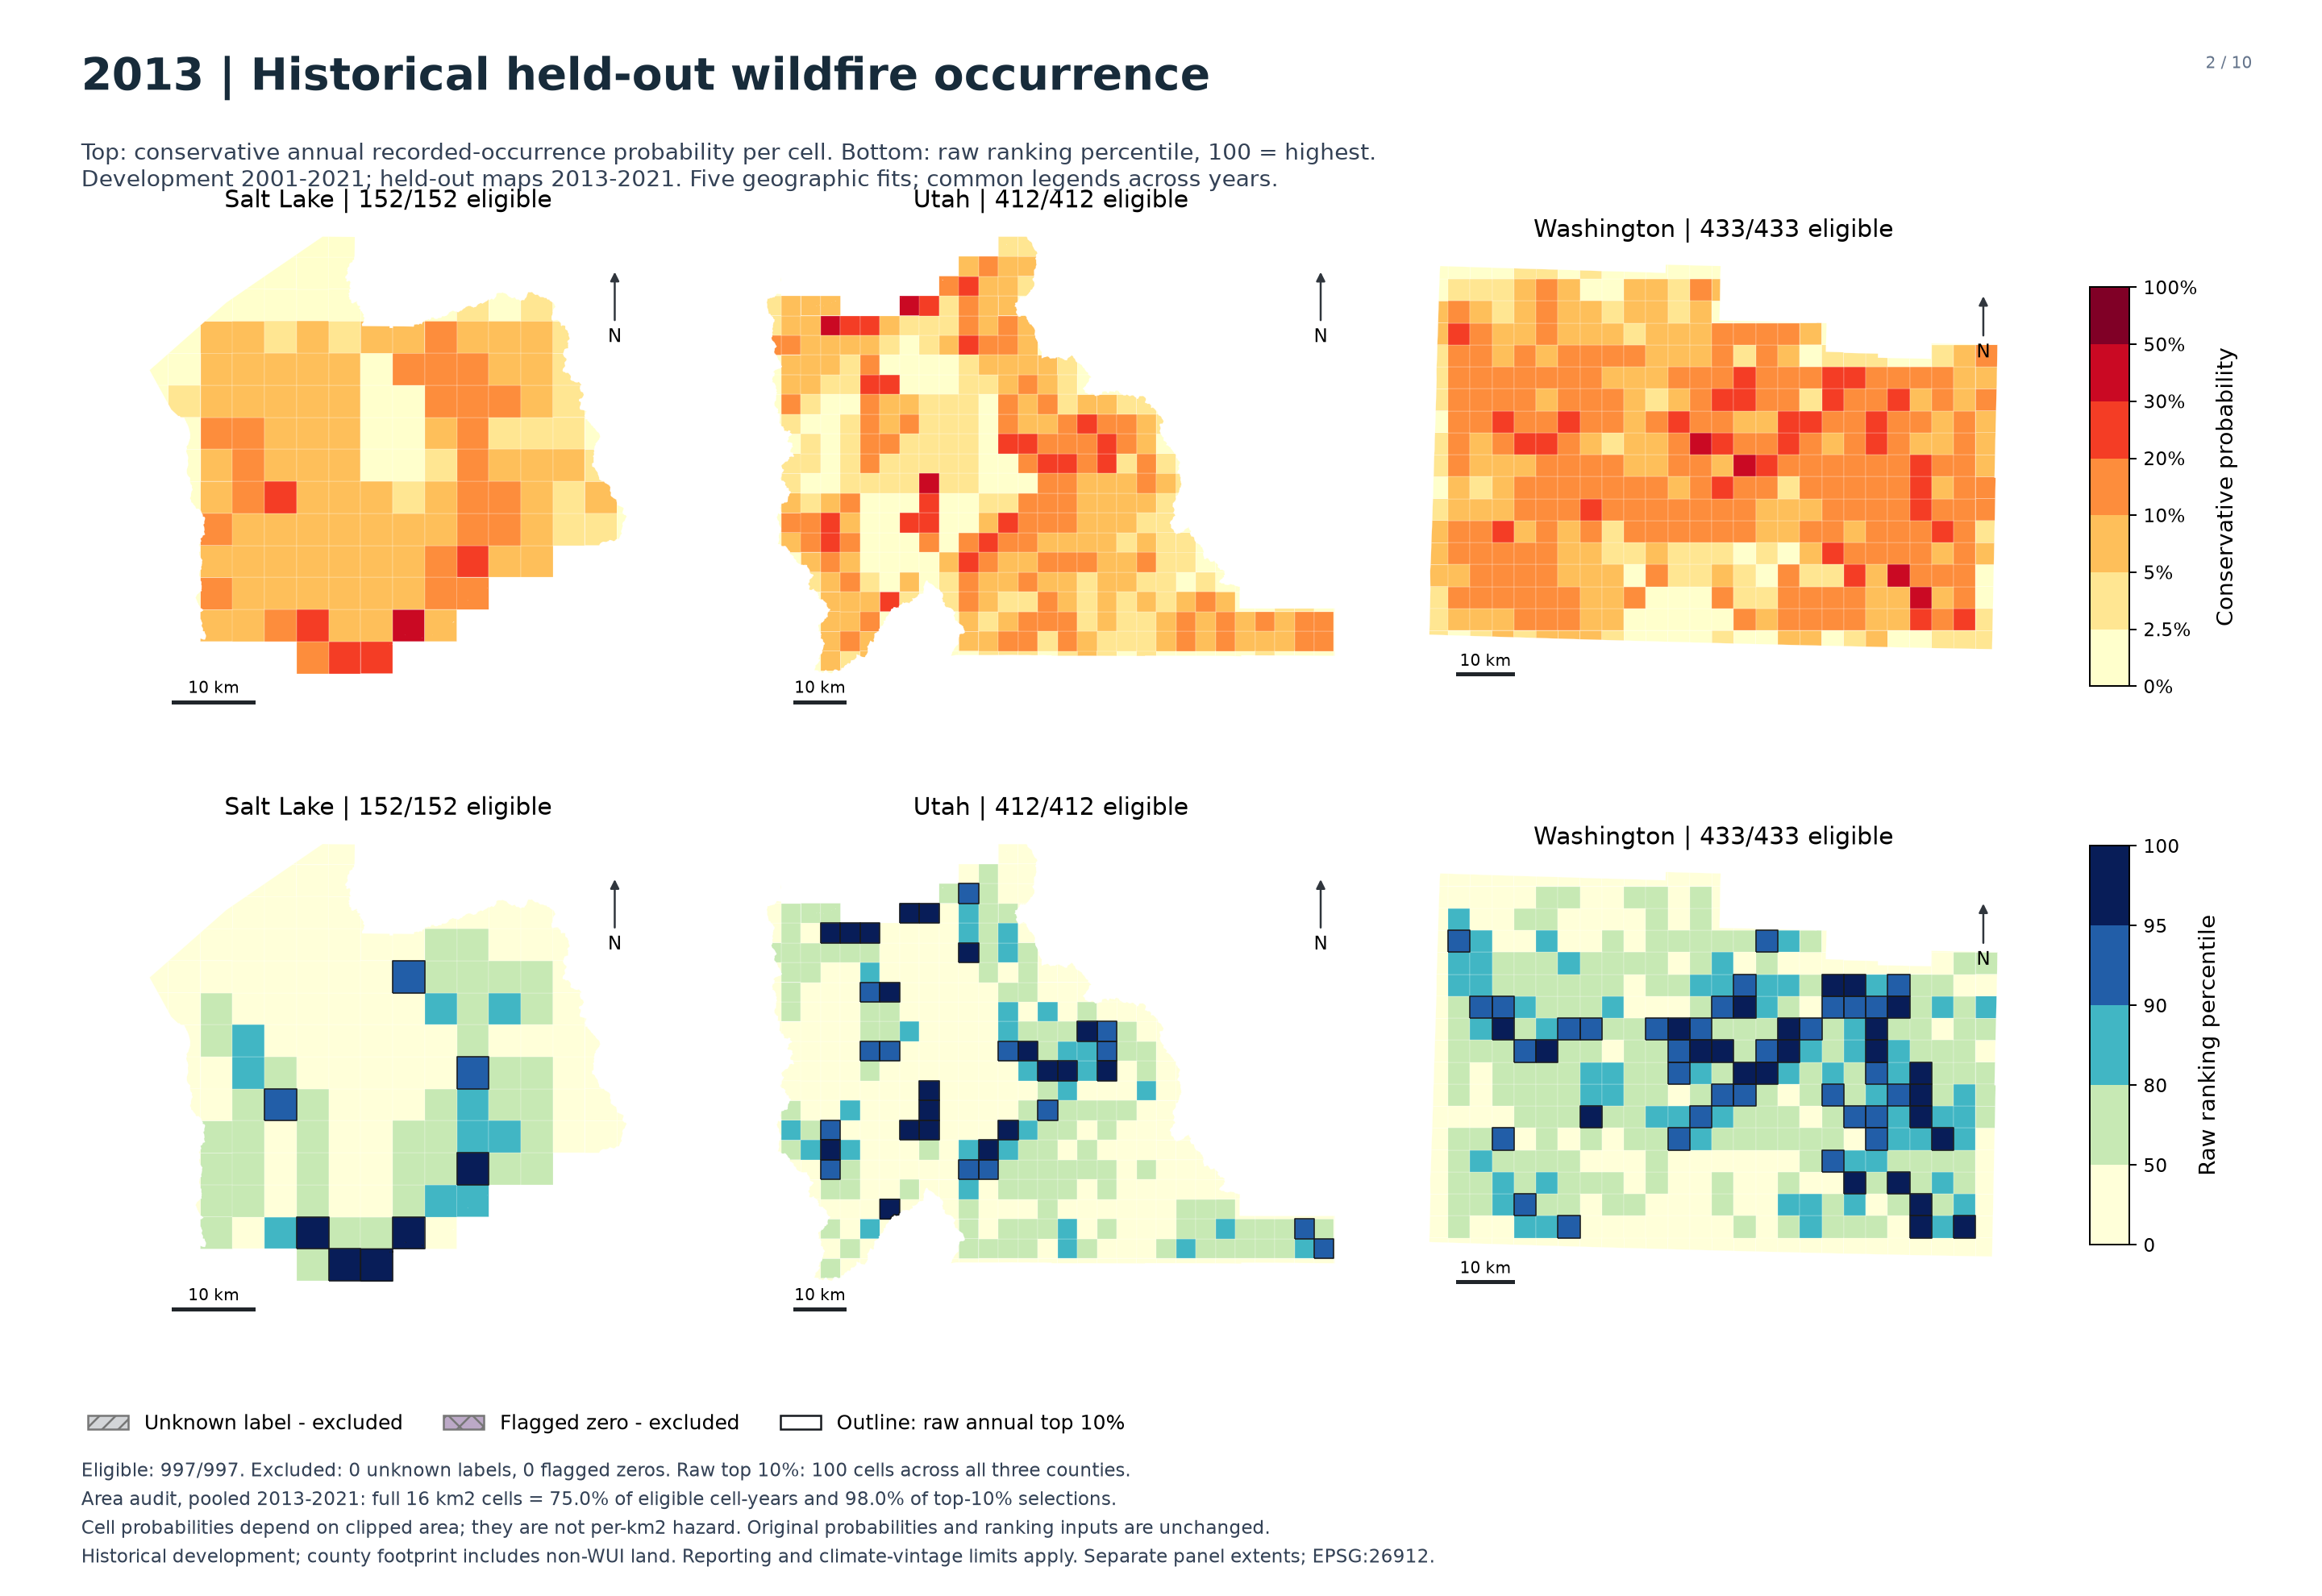

2013: 997 of 997 original cells have held-out predictions; 0 unknown-label and 0 flagged-zero cells are excluded. Outlines select 100 cells across the three-county cohort. In this year, full cells represent 75.6% of eligible cells and 99.0% of raw top-decile selections. Upper panels show conservative probabilities; lower panels show raw ranking percentiles. Original-area values are retained, and boundary-cell probabilities are not per-km² hazard measures. Development years informed model selection; terrain is a contemporary static proxy.

Geographic comparison among eligible cells: Salt Lake has mean conservative probability 7.19% and 8 raw top-decile cells; Utah has mean conservative probability 7.59% and 34 raw top-decile cells; Washington has mean conservative probability 10.59% and 58 raw top-decile cells. County averages do not imply uniform conditions within a county; the mapped pattern is clustered, and panel scales differ.

In [3]:
item = maps[0]
display(Markdown("## 2013 development holdout"))
display(Image(filename=str(ROOT / item["image"]), width=1100))
display(Markdown(item["caption"] + "\n\n" + item["spatial_description"]))

## 2014 development holdout

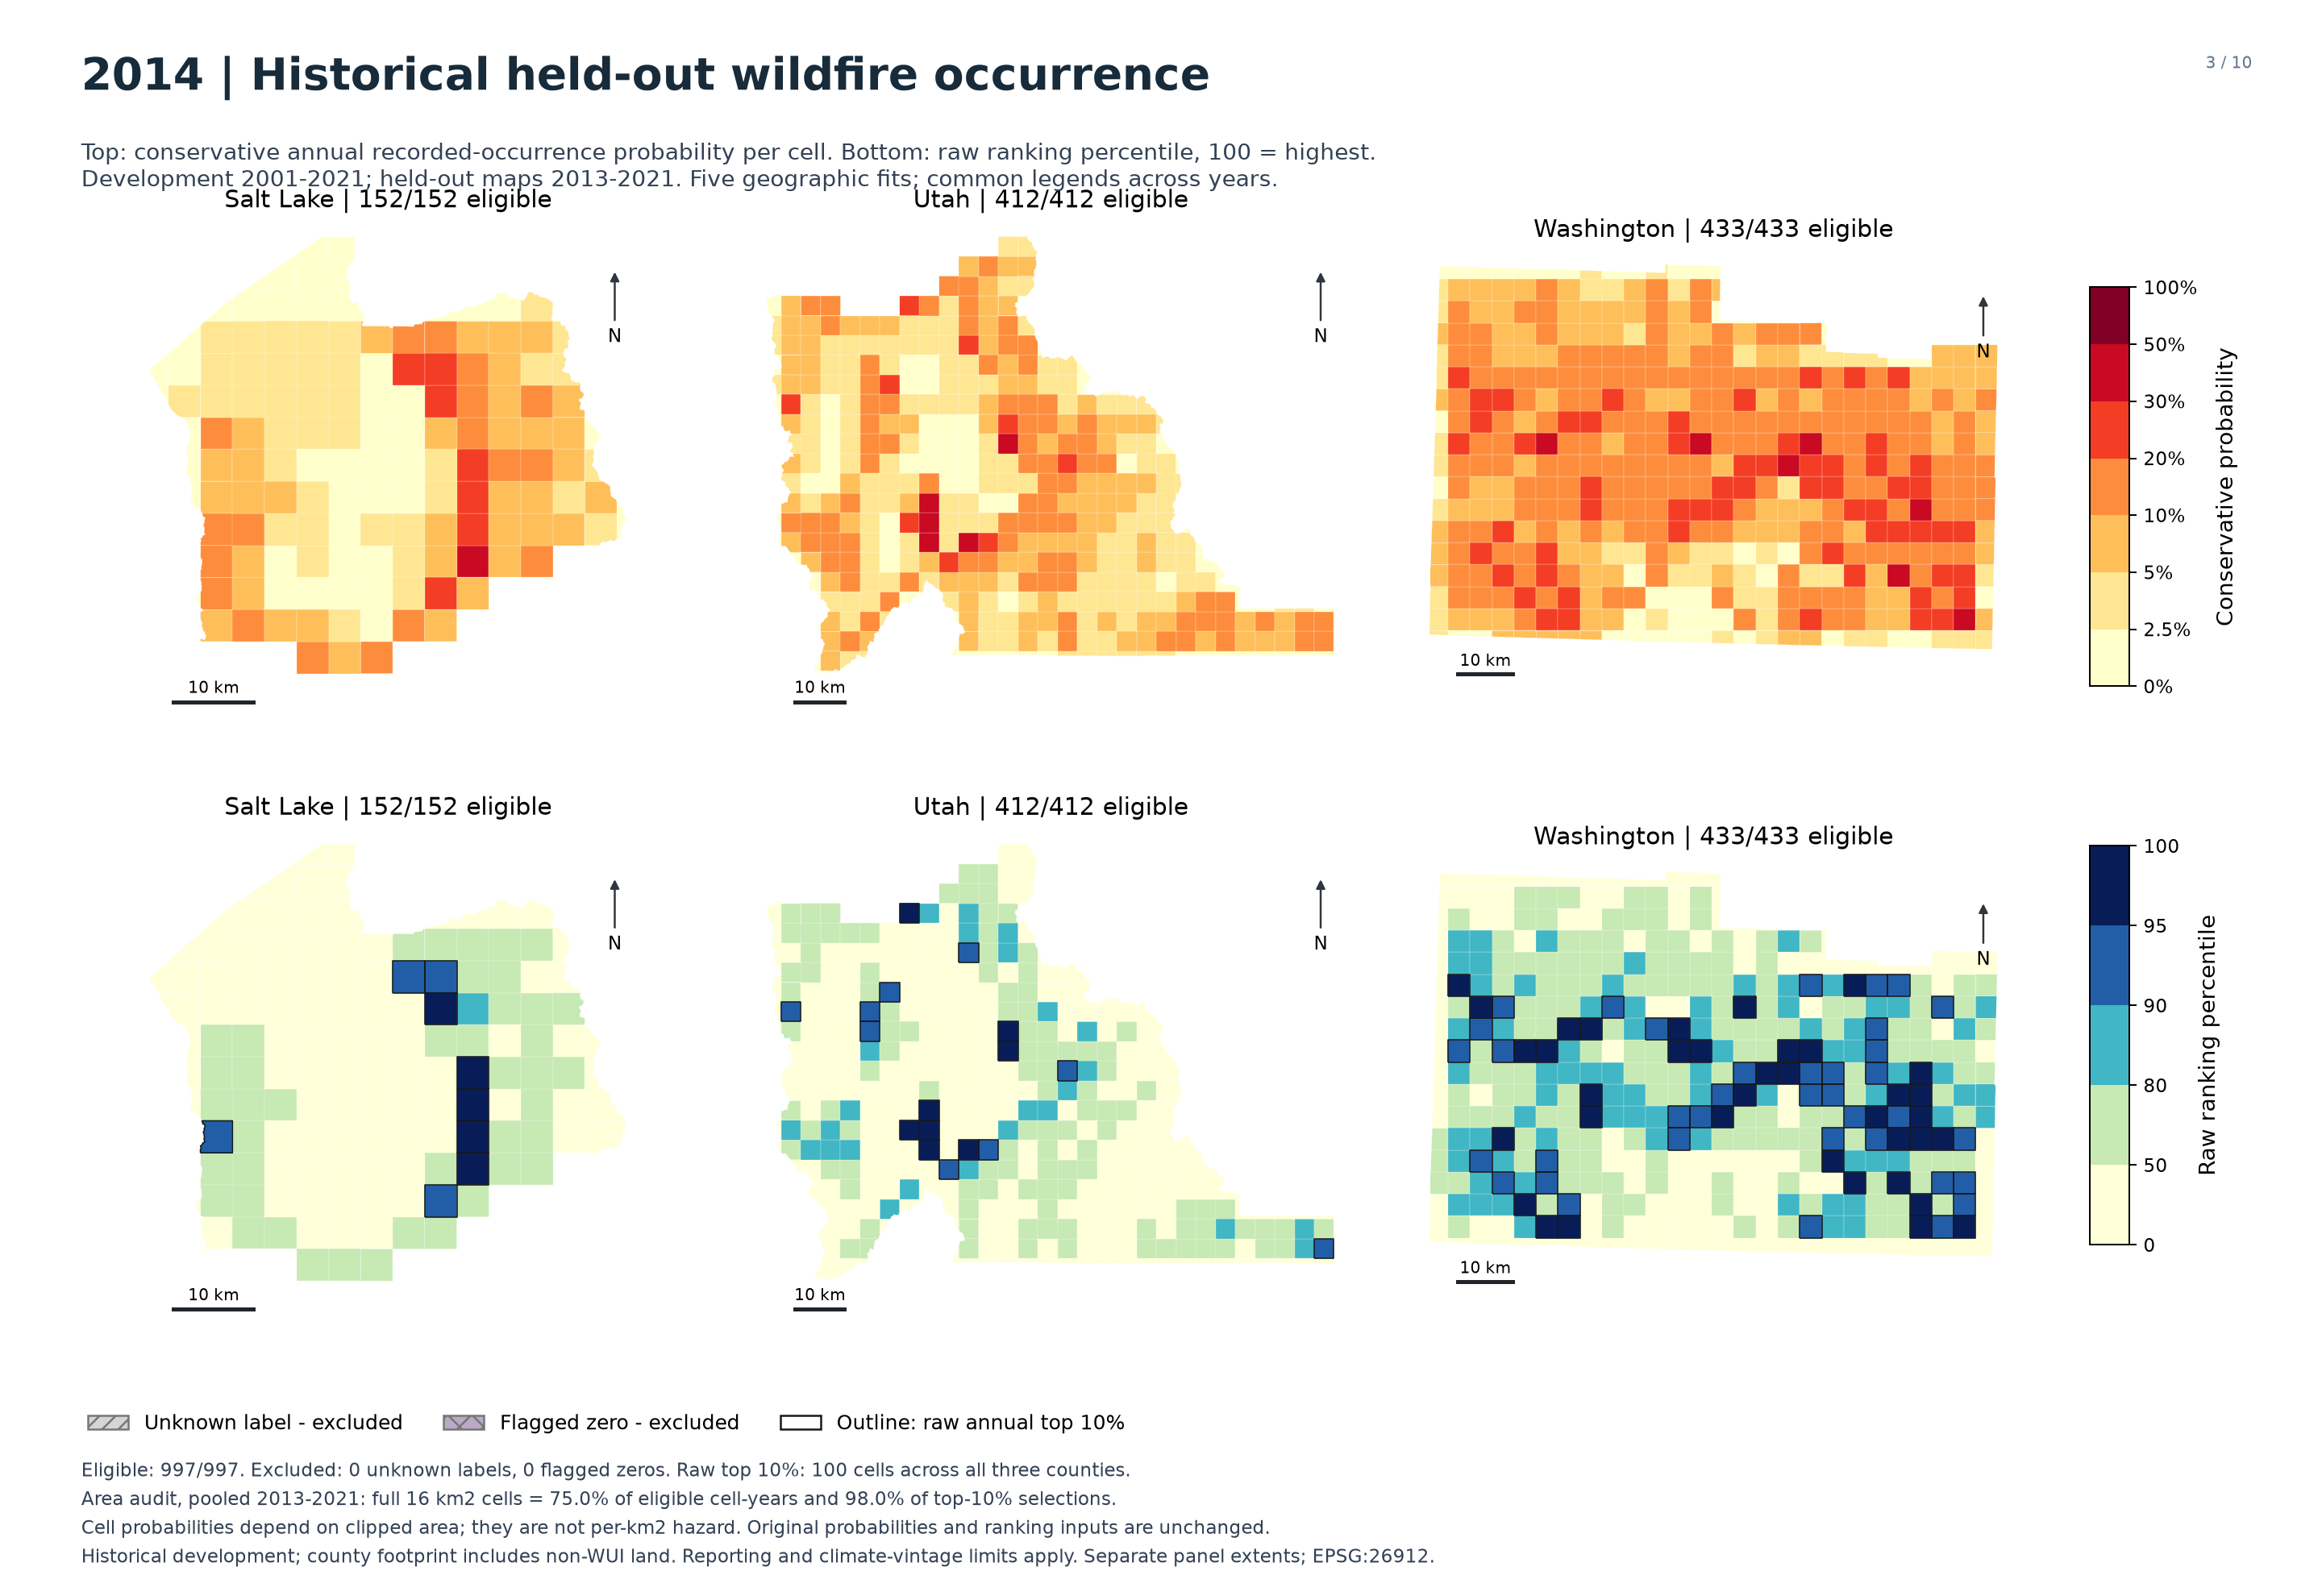

2014: 997 of 997 original cells have held-out predictions; 0 unknown-label and 0 flagged-zero cells are excluded. Outlines select 100 cells across the three-county cohort. In this year, full cells represent 75.6% of eligible cells and 99.0% of raw top-decile selections. Upper panels show conservative probabilities; lower panels show raw ranking percentiles. Original-area values are retained, and boundary-cell probabilities are not per-km² hazard measures. Development years informed model selection; terrain is a contemporary static proxy.

Geographic comparison among eligible cells: Salt Lake has mean conservative probability 5.99% and 9 raw top-decile cells; Utah has mean conservative probability 6.93% and 17 raw top-decile cells; Washington has mean conservative probability 12.01% and 74 raw top-decile cells. County averages do not imply uniform conditions within a county; the mapped pattern is clustered, and panel scales differ.

In [4]:
item = maps[1]
display(Markdown("## 2014 development holdout"))
display(Image(filename=str(ROOT / item["image"]), width=1100))
display(Markdown(item["caption"] + "\n\n" + item["spatial_description"]))

## 2015 development holdout

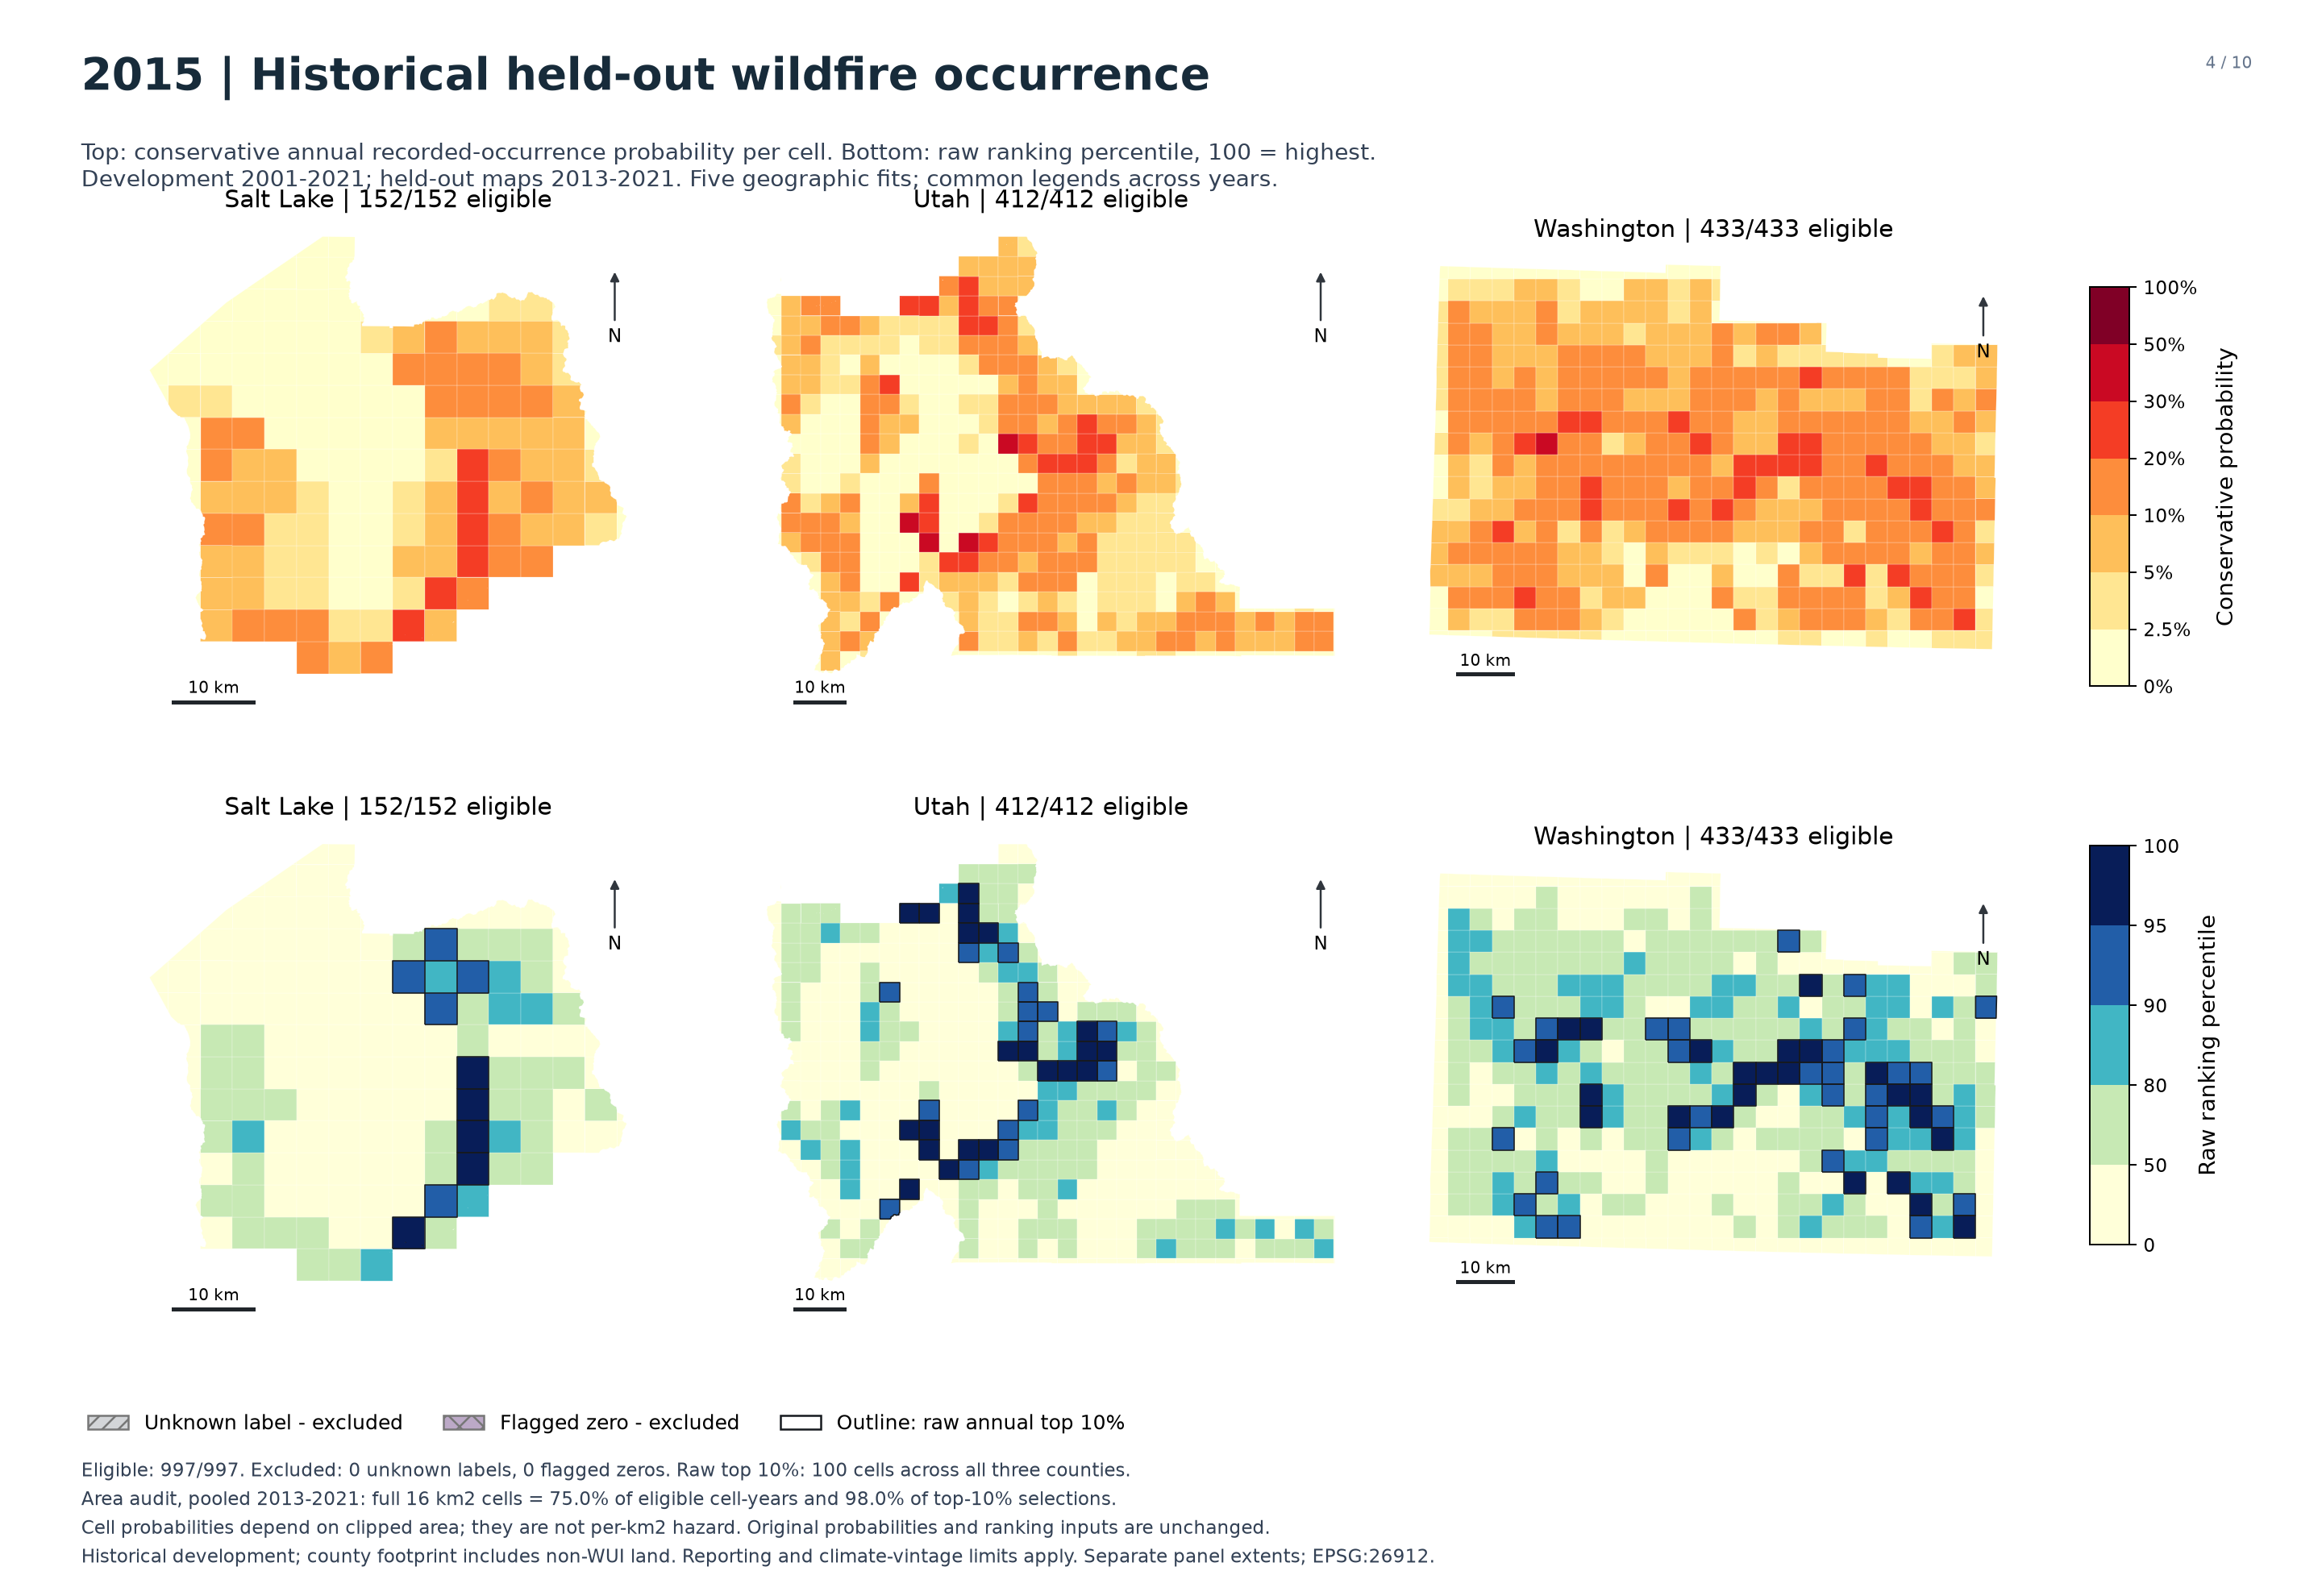

2015: 997 of 997 original cells have held-out predictions; 0 unknown-label and 0 flagged-zero cells are excluded. Outlines select 100 cells across the three-county cohort. In this year, full cells represent 75.6% of eligible cells and 98.0% of raw top-decile selections. Upper panels show conservative probabilities; lower panels show raw ranking percentiles. Original-area values are retained, and boundary-cell probabilities are not per-km² hazard measures. Development years informed model selection; terrain is a contemporary static proxy.

Geographic comparison among eligible cells: Salt Lake has mean conservative probability 6.03% and 10 raw top-decile cells; Utah has mean conservative probability 7.26% and 36 raw top-decile cells; Washington has mean conservative probability 9.58% and 54 raw top-decile cells. County averages do not imply uniform conditions within a county; the mapped pattern is clustered, and panel scales differ.

In [5]:
item = maps[2]
display(Markdown("## 2015 development holdout"))
display(Image(filename=str(ROOT / item["image"]), width=1100))
display(Markdown(item["caption"] + "\n\n" + item["spatial_description"]))

## 2016 development holdout

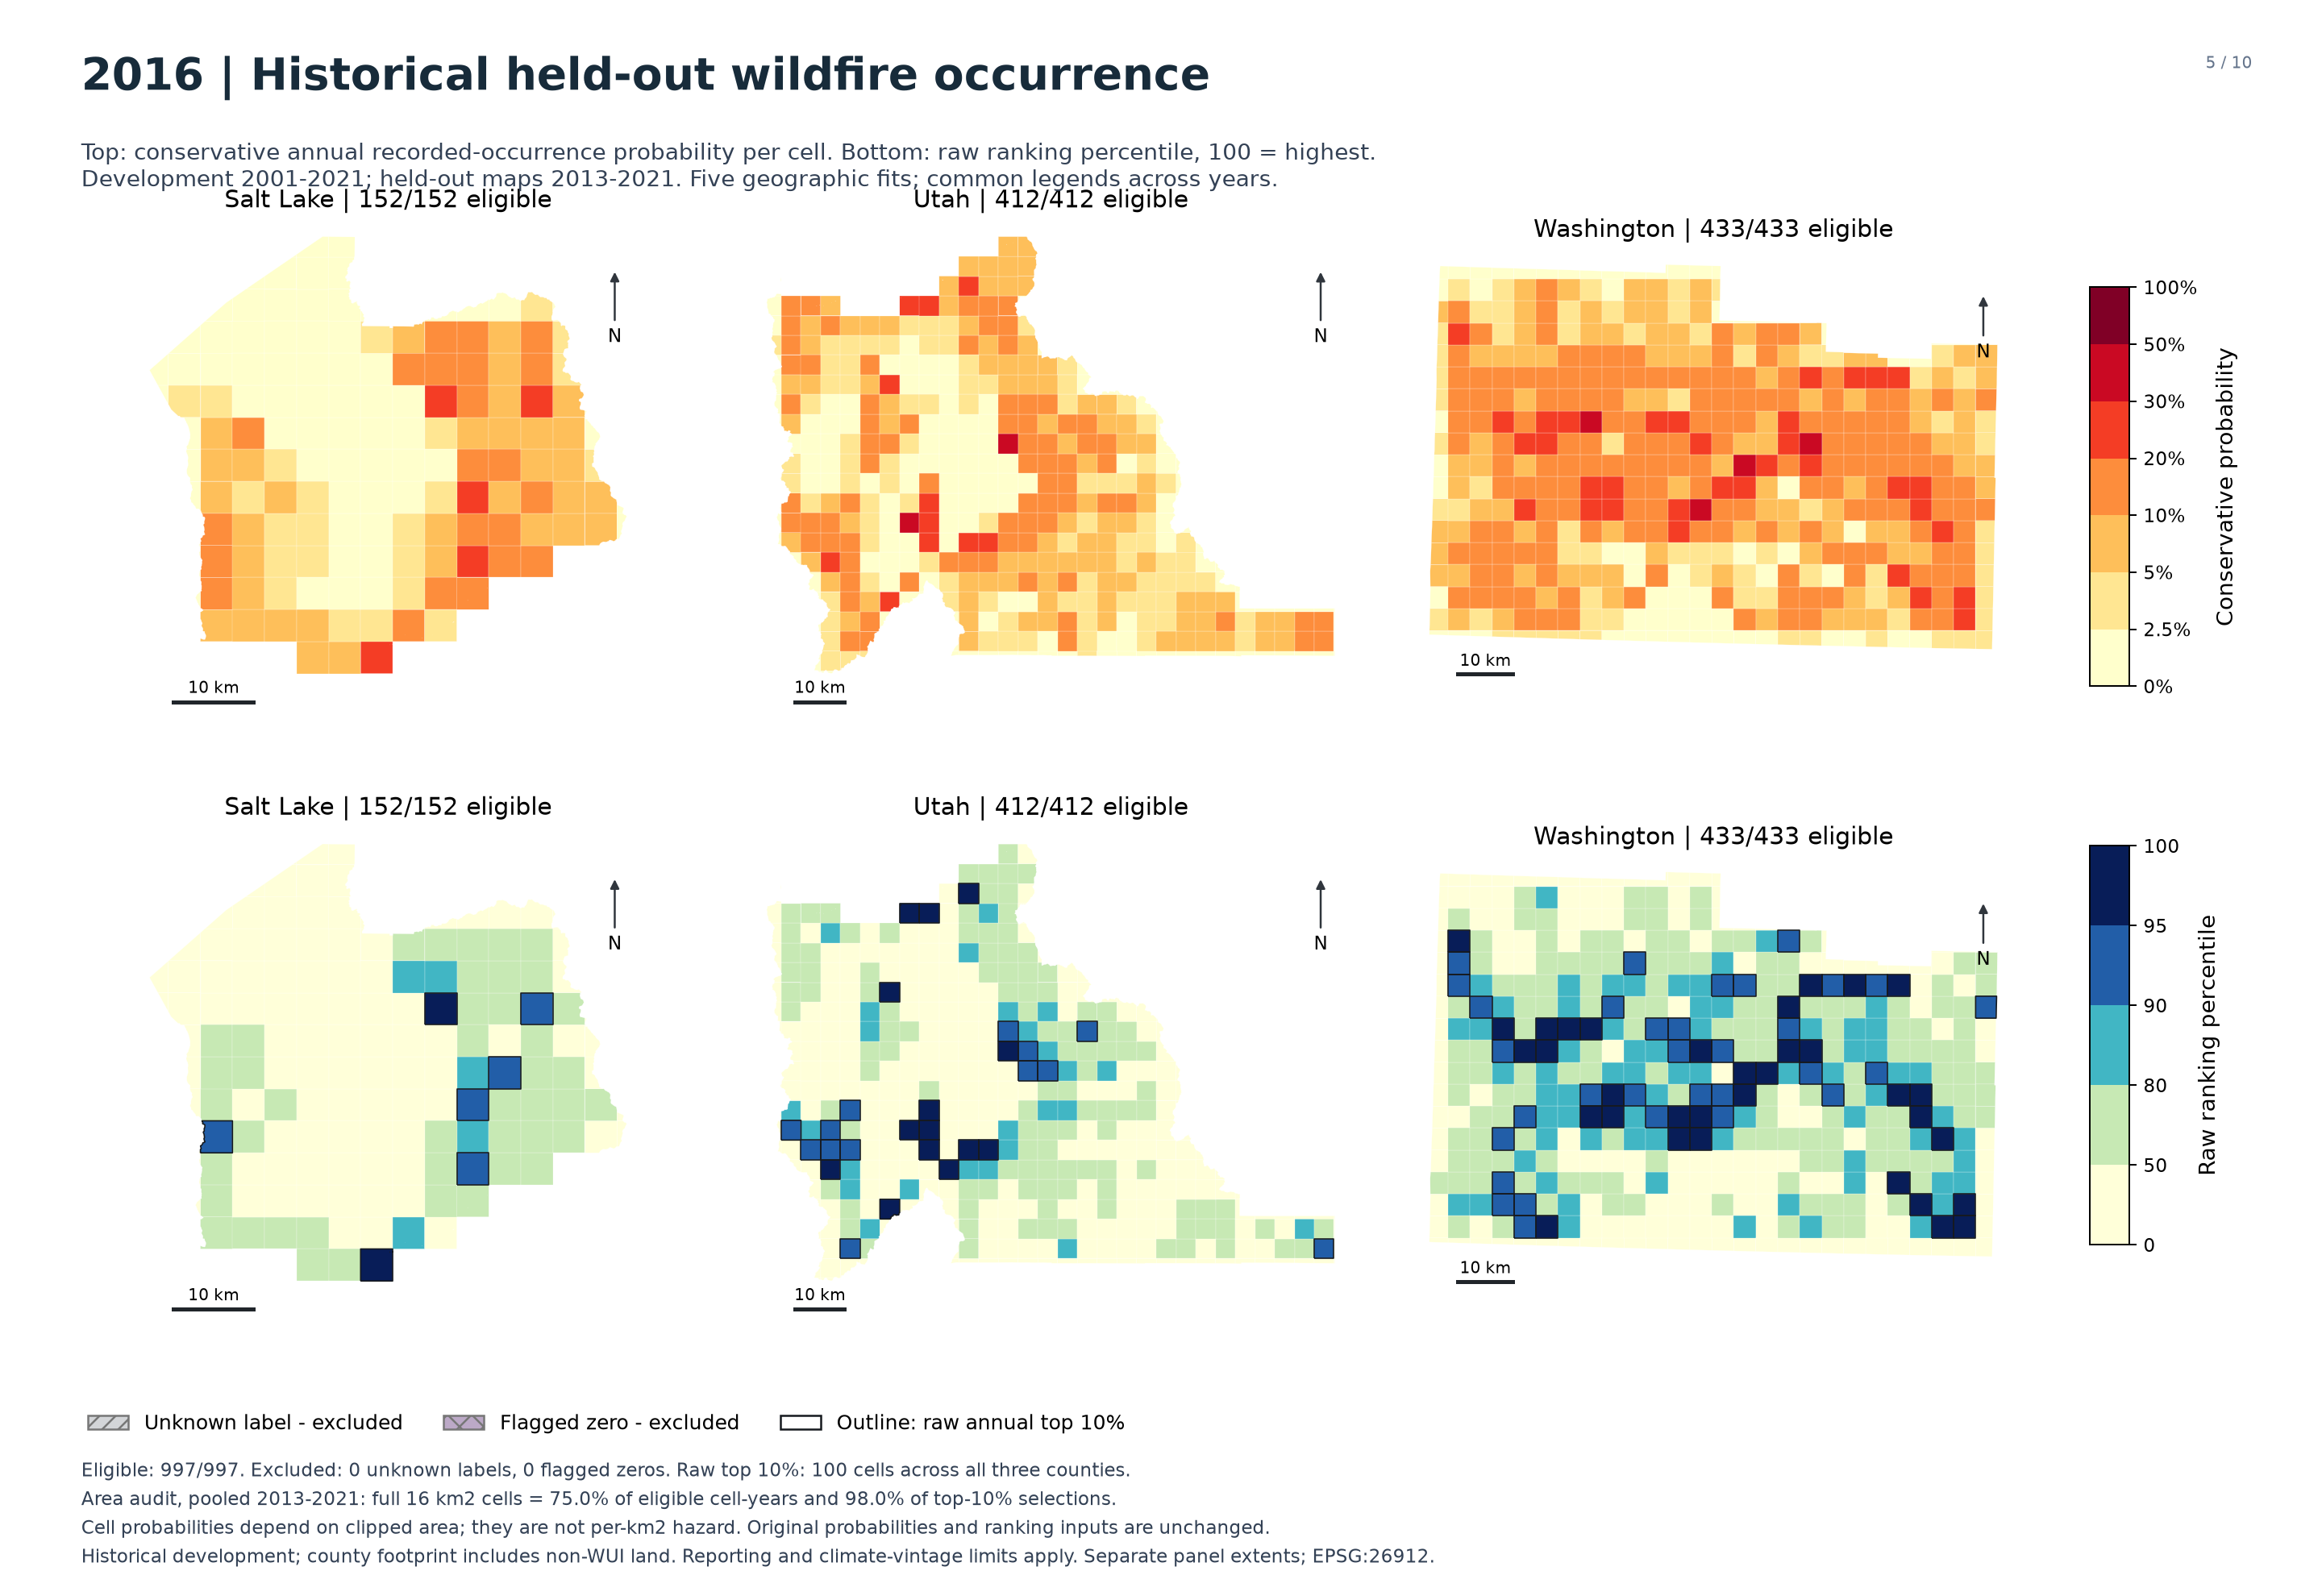

2016: 997 of 997 original cells have held-out predictions; 0 unknown-label and 0 flagged-zero cells are excluded. Outlines select 100 cells across the three-county cohort. In this year, full cells represent 75.6% of eligible cells and 96.0% of raw top-decile selections. Upper panels show conservative probabilities; lower panels show raw ranking percentiles. Original-area values are retained, and boundary-cell probabilities are not per-km² hazard measures. Development years informed model selection; terrain is a contemporary static proxy.

Geographic comparison among eligible cells: Salt Lake has mean conservative probability 5.61% and 7 raw top-decile cells; Utah has mean conservative probability 6.32% and 27 raw top-decile cells; Washington has mean conservative probability 9.95% and 66 raw top-decile cells. County averages do not imply uniform conditions within a county; the mapped pattern is clustered, and panel scales differ.

In [6]:
item = maps[3]
display(Markdown("## 2016 development holdout"))
display(Image(filename=str(ROOT / item["image"]), width=1100))
display(Markdown(item["caption"] + "\n\n" + item["spatial_description"]))

## 2017 development holdout

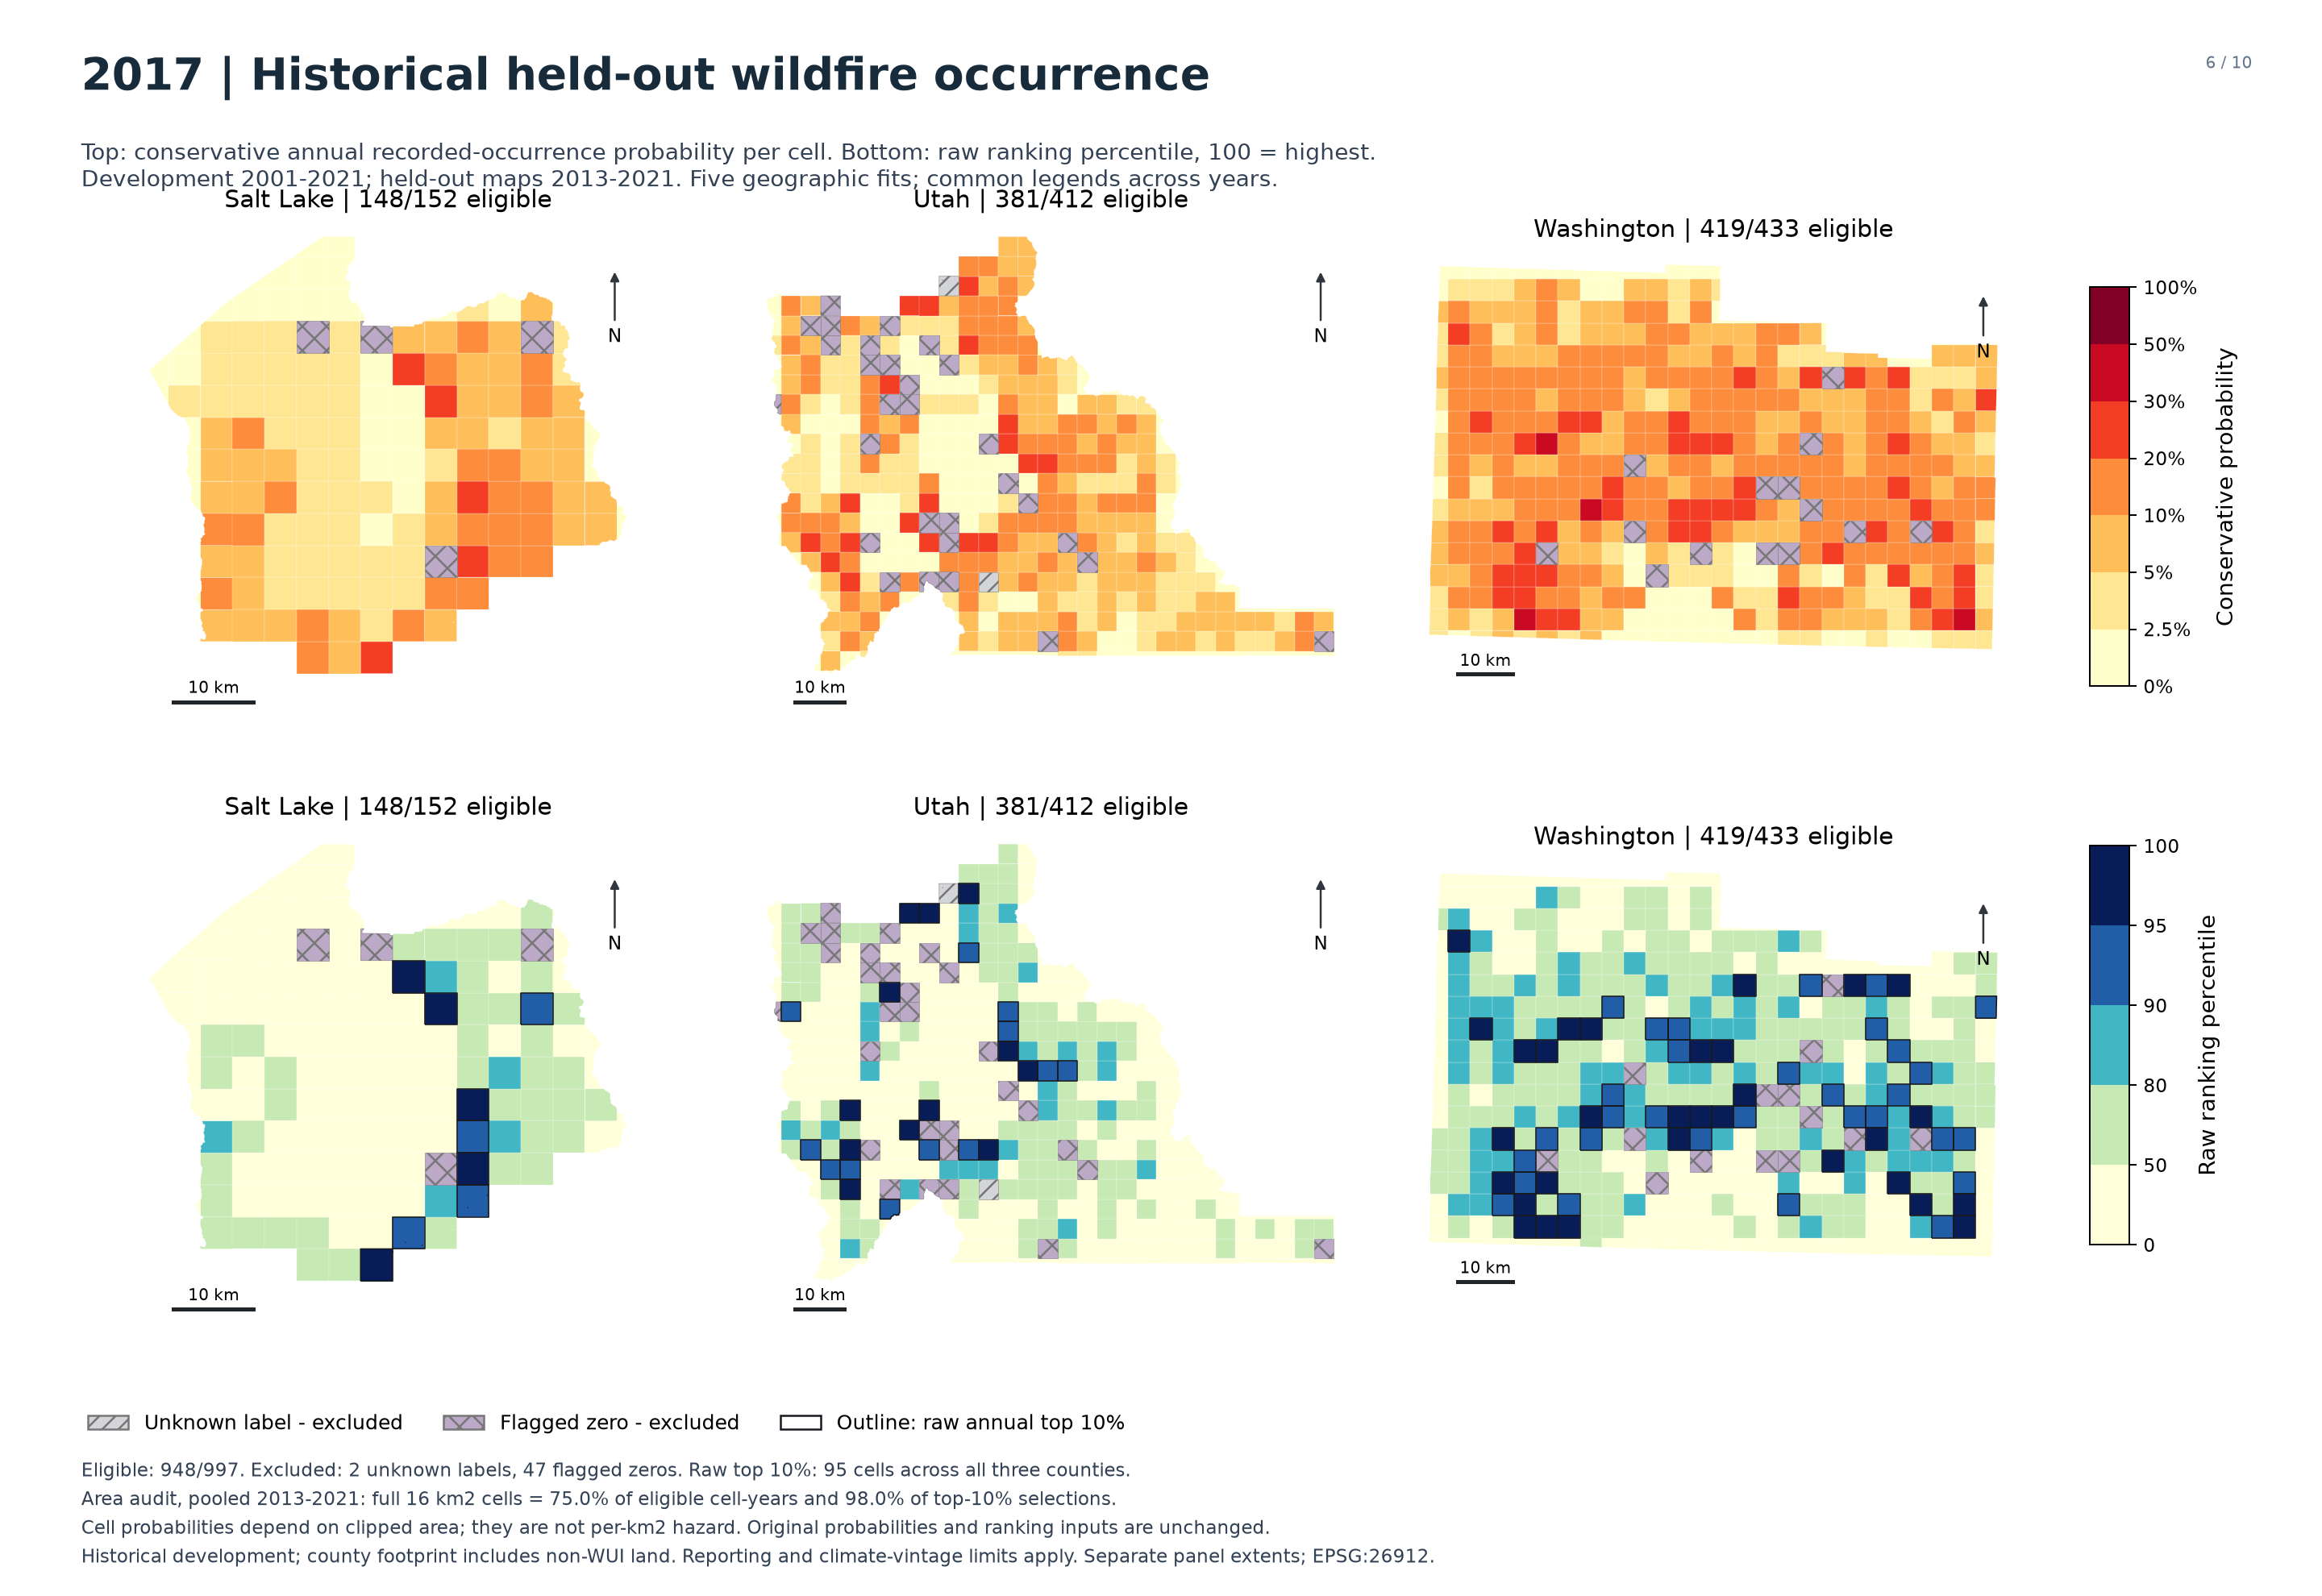

2017: 948 of 997 original cells have held-out predictions; 2 unknown-label and 47 flagged-zero cells are excluded. Outlines select 95 cells across the three-county cohort. In this year, full cells represent 74.8% of eligible cells and 97.9% of raw top-decile selections. Upper panels show conservative probabilities; lower panels show raw ranking percentiles. Original-area values are retained, and boundary-cell probabilities are not per-km² hazard measures. Development years informed model selection; terrain is a contemporary static proxy.

Geographic comparison among eligible cells: Salt Lake has mean conservative probability 6.07% and 9 raw top-decile cells; Utah has mean conservative probability 6.63% and 24 raw top-decile cells; Washington has mean conservative probability 10.66% and 62 raw top-decile cells. County averages do not imply uniform conditions within a county; the mapped pattern is clustered, and panel scales differ.

In [7]:
item = maps[4]
display(Markdown("## 2017 development holdout"))
display(Image(filename=str(ROOT / item["image"]), width=1100))
display(Markdown(item["caption"] + "\n\n" + item["spatial_description"]))

## 2018 development holdout

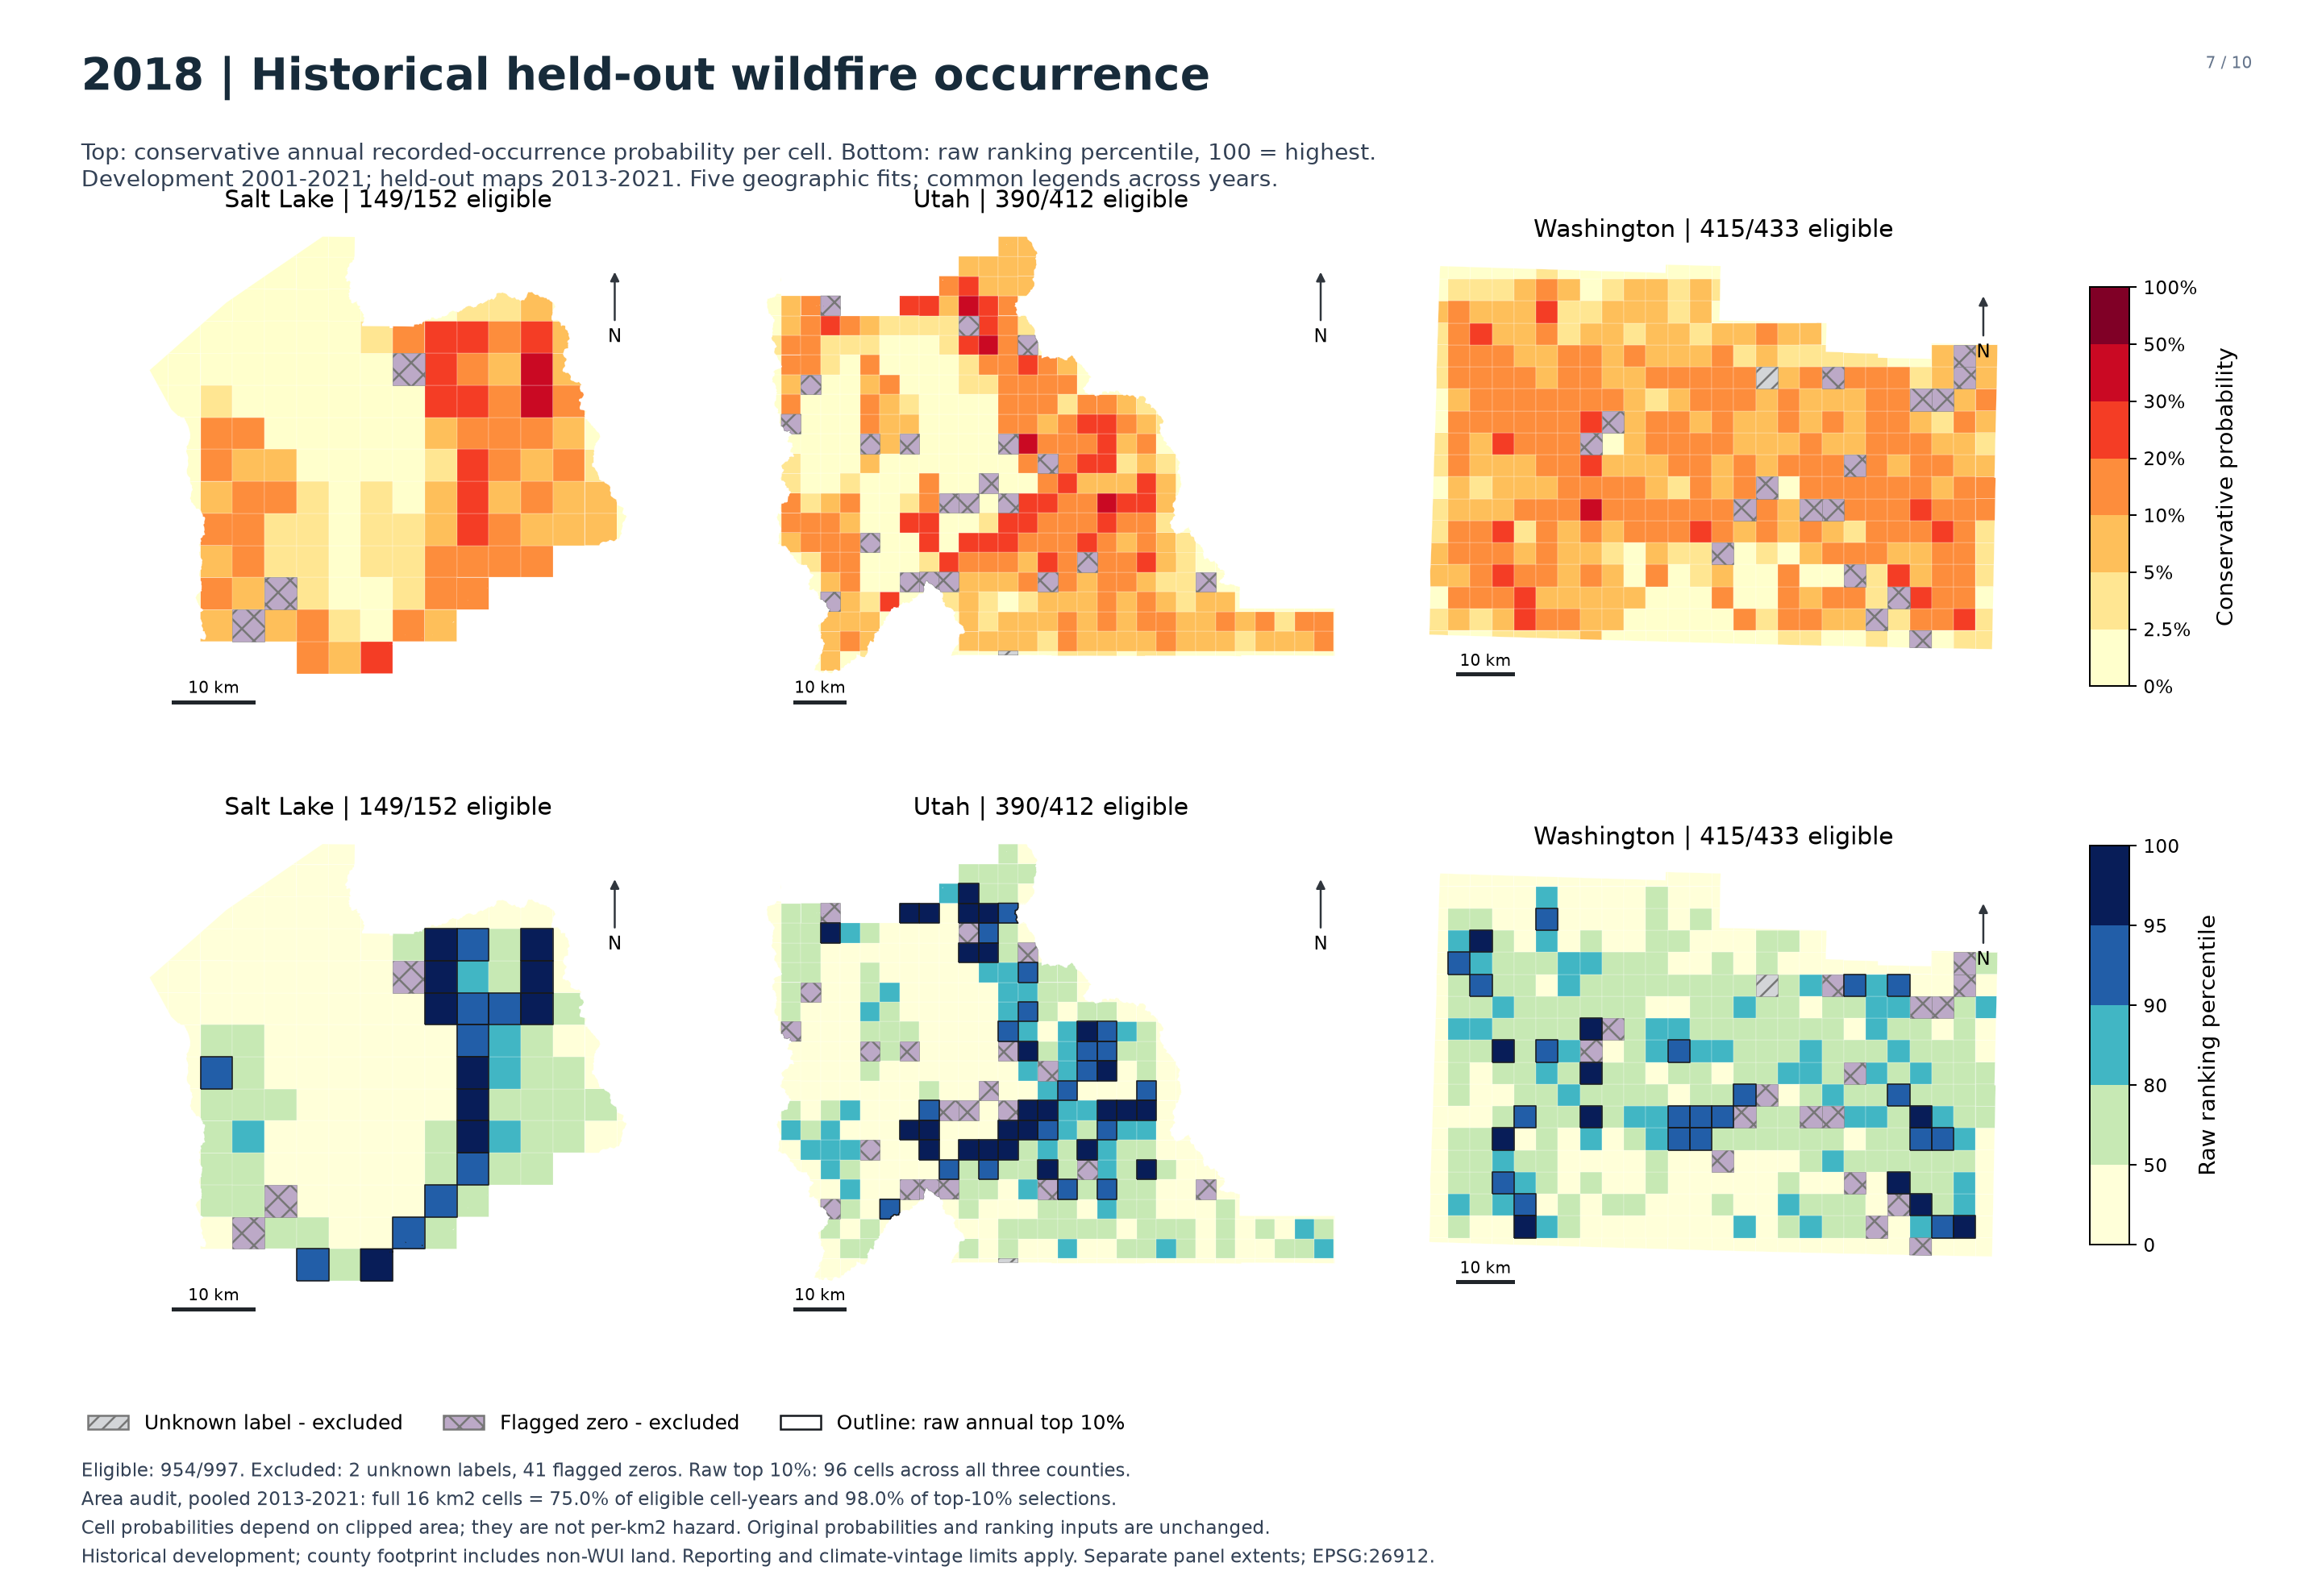

2018: 954 of 997 original cells have held-out predictions; 2 unknown-label and 41 flagged-zero cells are excluded. Outlines select 96 cells across the three-county cohort. In this year, full cells represent 75.3% of eligible cells and 97.9% of raw top-decile selections. Upper panels show conservative probabilities; lower panels show raw ranking percentiles. Original-area values are retained, and boundary-cell probabilities are not per-km² hazard measures. Development years informed model selection; terrain is a contemporary static proxy.

Geographic comparison among eligible cells: Salt Lake has mean conservative probability 7.14% and 19 raw top-decile cells; Utah has mean conservative probability 8.08% and 46 raw top-decile cells; Washington has mean conservative probability 9.02% and 31 raw top-decile cells. County averages do not imply uniform conditions within a county; the mapped pattern is clustered, and panel scales differ.

In [8]:
item = maps[5]
display(Markdown("## 2018 development holdout"))
display(Image(filename=str(ROOT / item["image"]), width=1100))
display(Markdown(item["caption"] + "\n\n" + item["spatial_description"]))

## 2019 development holdout

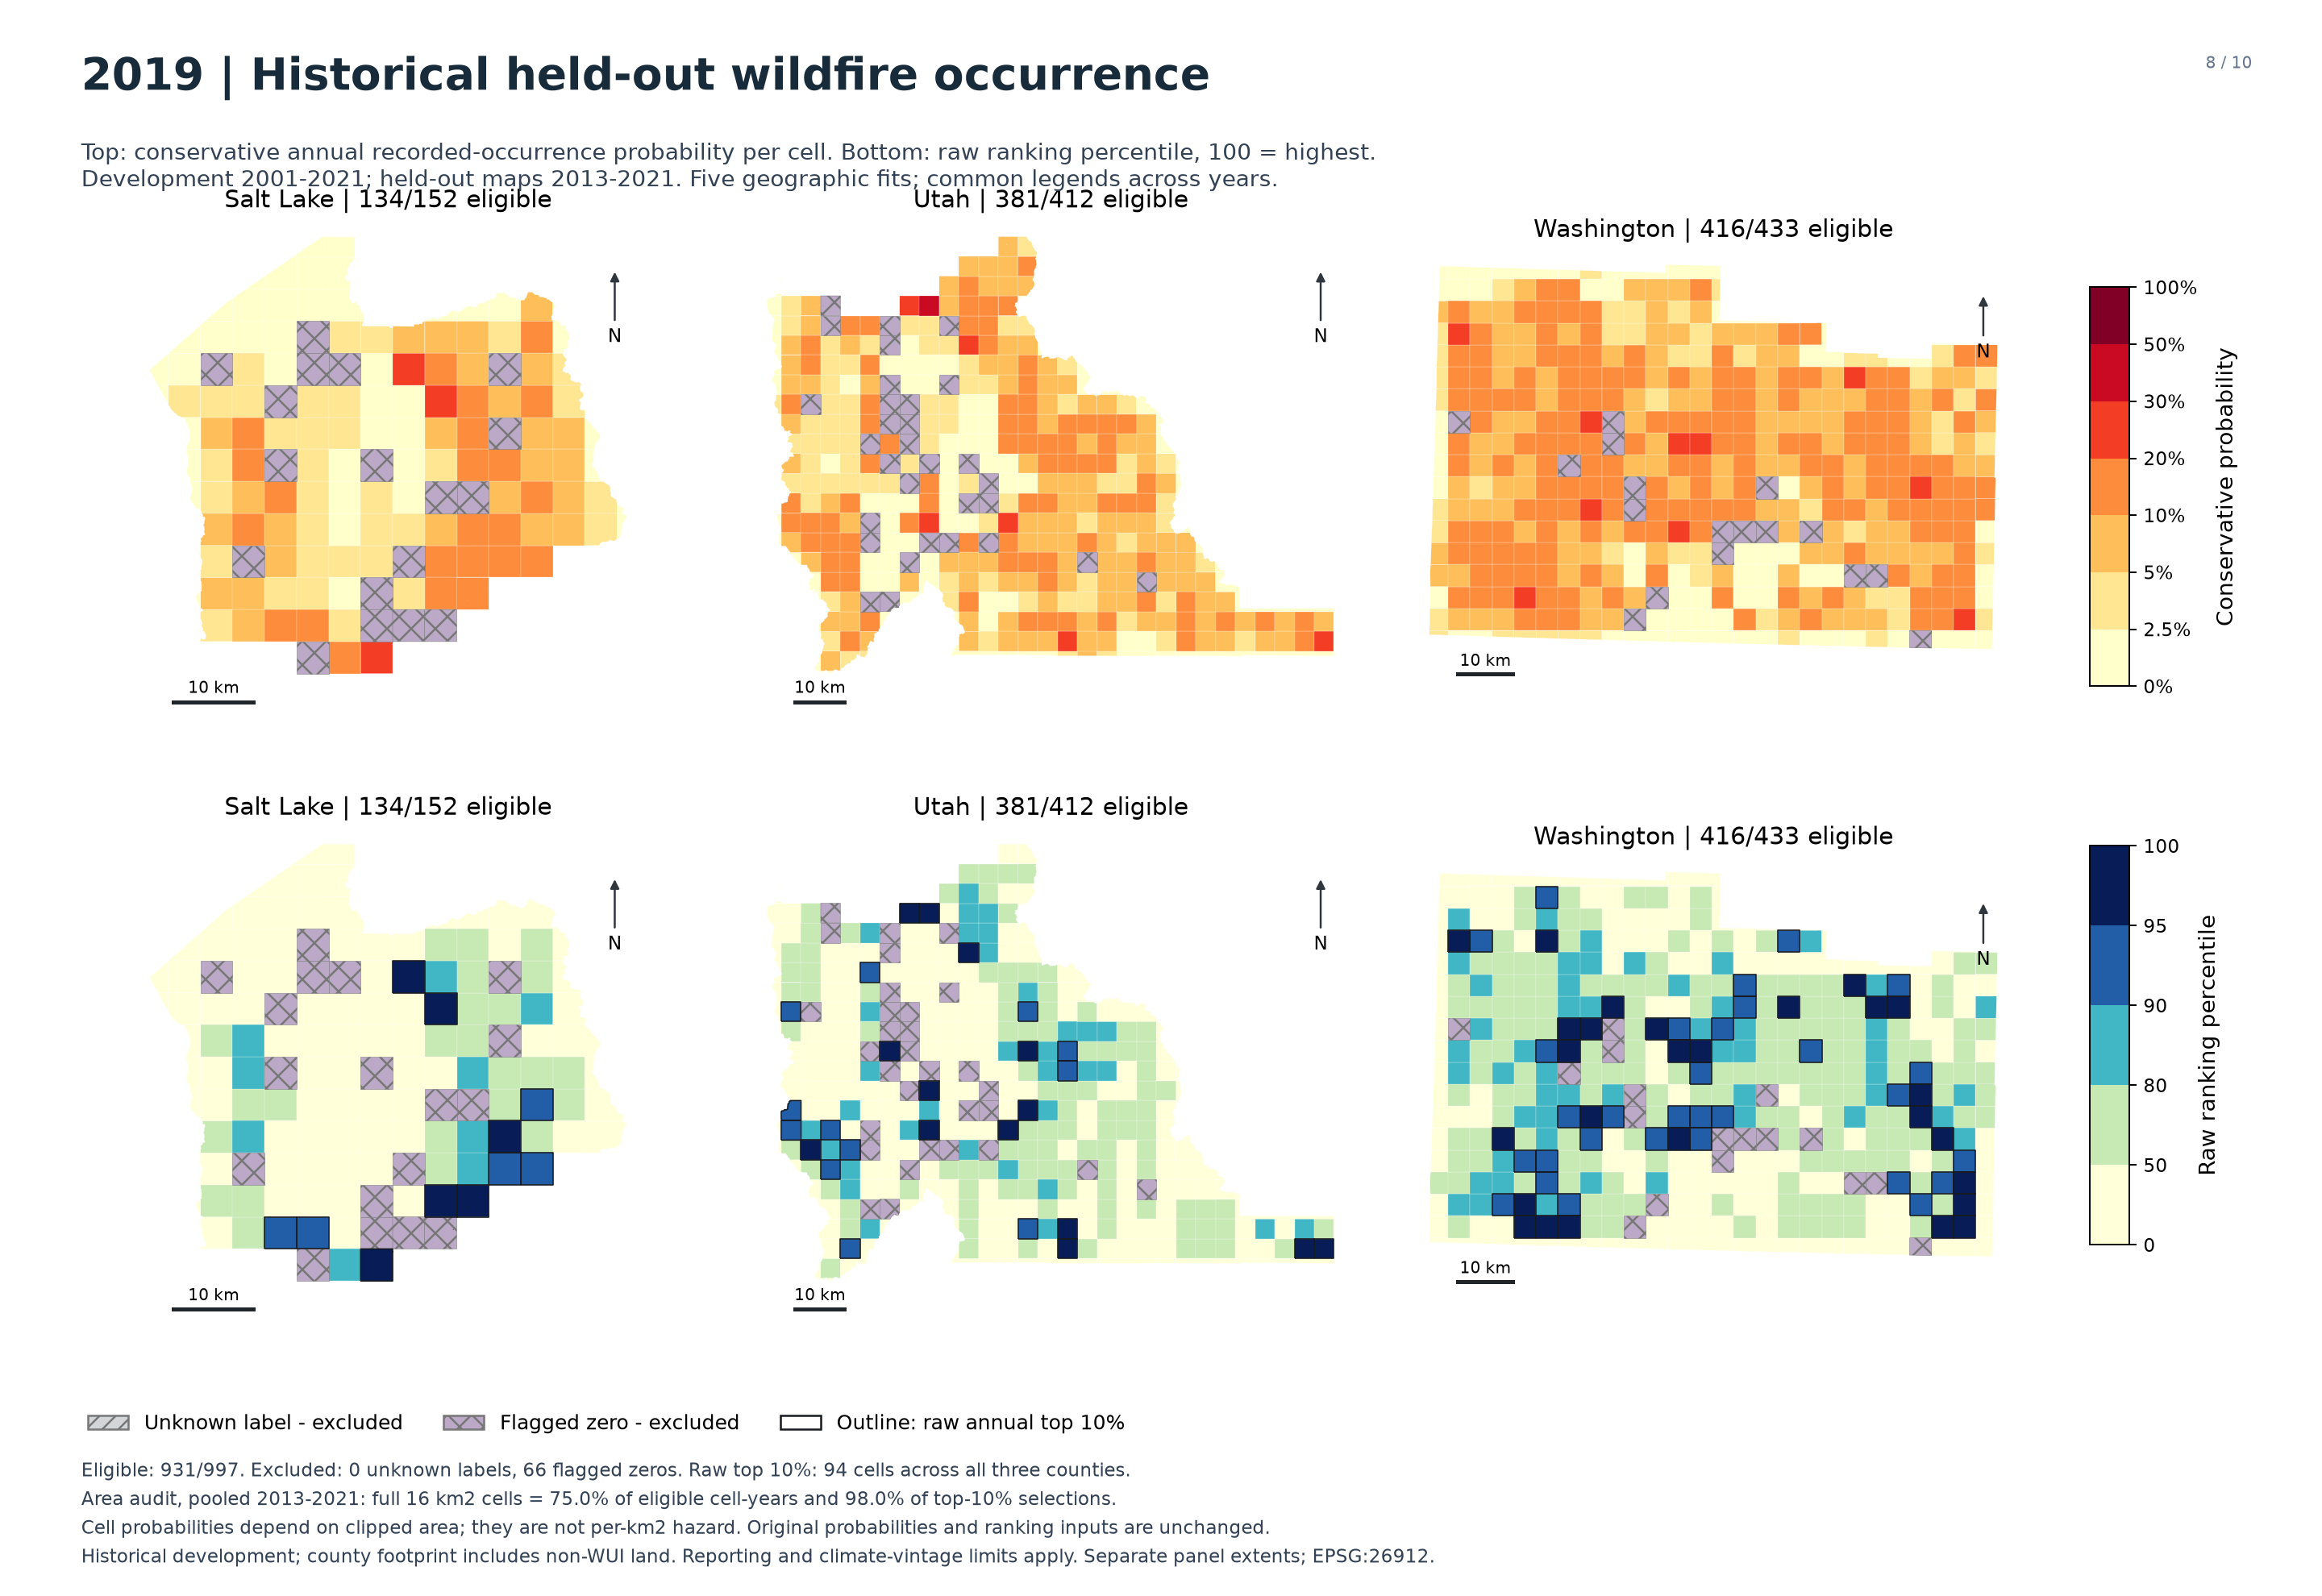

2019: 931 of 997 original cells have held-out predictions; 0 unknown-label and 66 flagged-zero cells are excluded. Outlines select 94 cells across the three-county cohort. In this year, full cells represent 74.1% of eligible cells and 97.9% of raw top-decile selections. Upper panels show conservative probabilities; lower panels show raw ranking percentiles. Original-area values are retained, and boundary-cell probabilities are not per-km² hazard measures. Development years informed model selection; terrain is a contemporary static proxy.

Geographic comparison among eligible cells: Salt Lake has mean conservative probability 5.80% and 11 raw top-decile cells; Utah has mean conservative probability 6.49% and 26 raw top-decile cells; Washington has mean conservative probability 8.71% and 57 raw top-decile cells. County averages do not imply uniform conditions within a county; the mapped pattern is clustered, and panel scales differ.

In [9]:
item = maps[6]
display(Markdown("## 2019 development holdout"))
display(Image(filename=str(ROOT / item["image"]), width=1100))
display(Markdown(item["caption"] + "\n\n" + item["spatial_description"]))

## 2020 development holdout

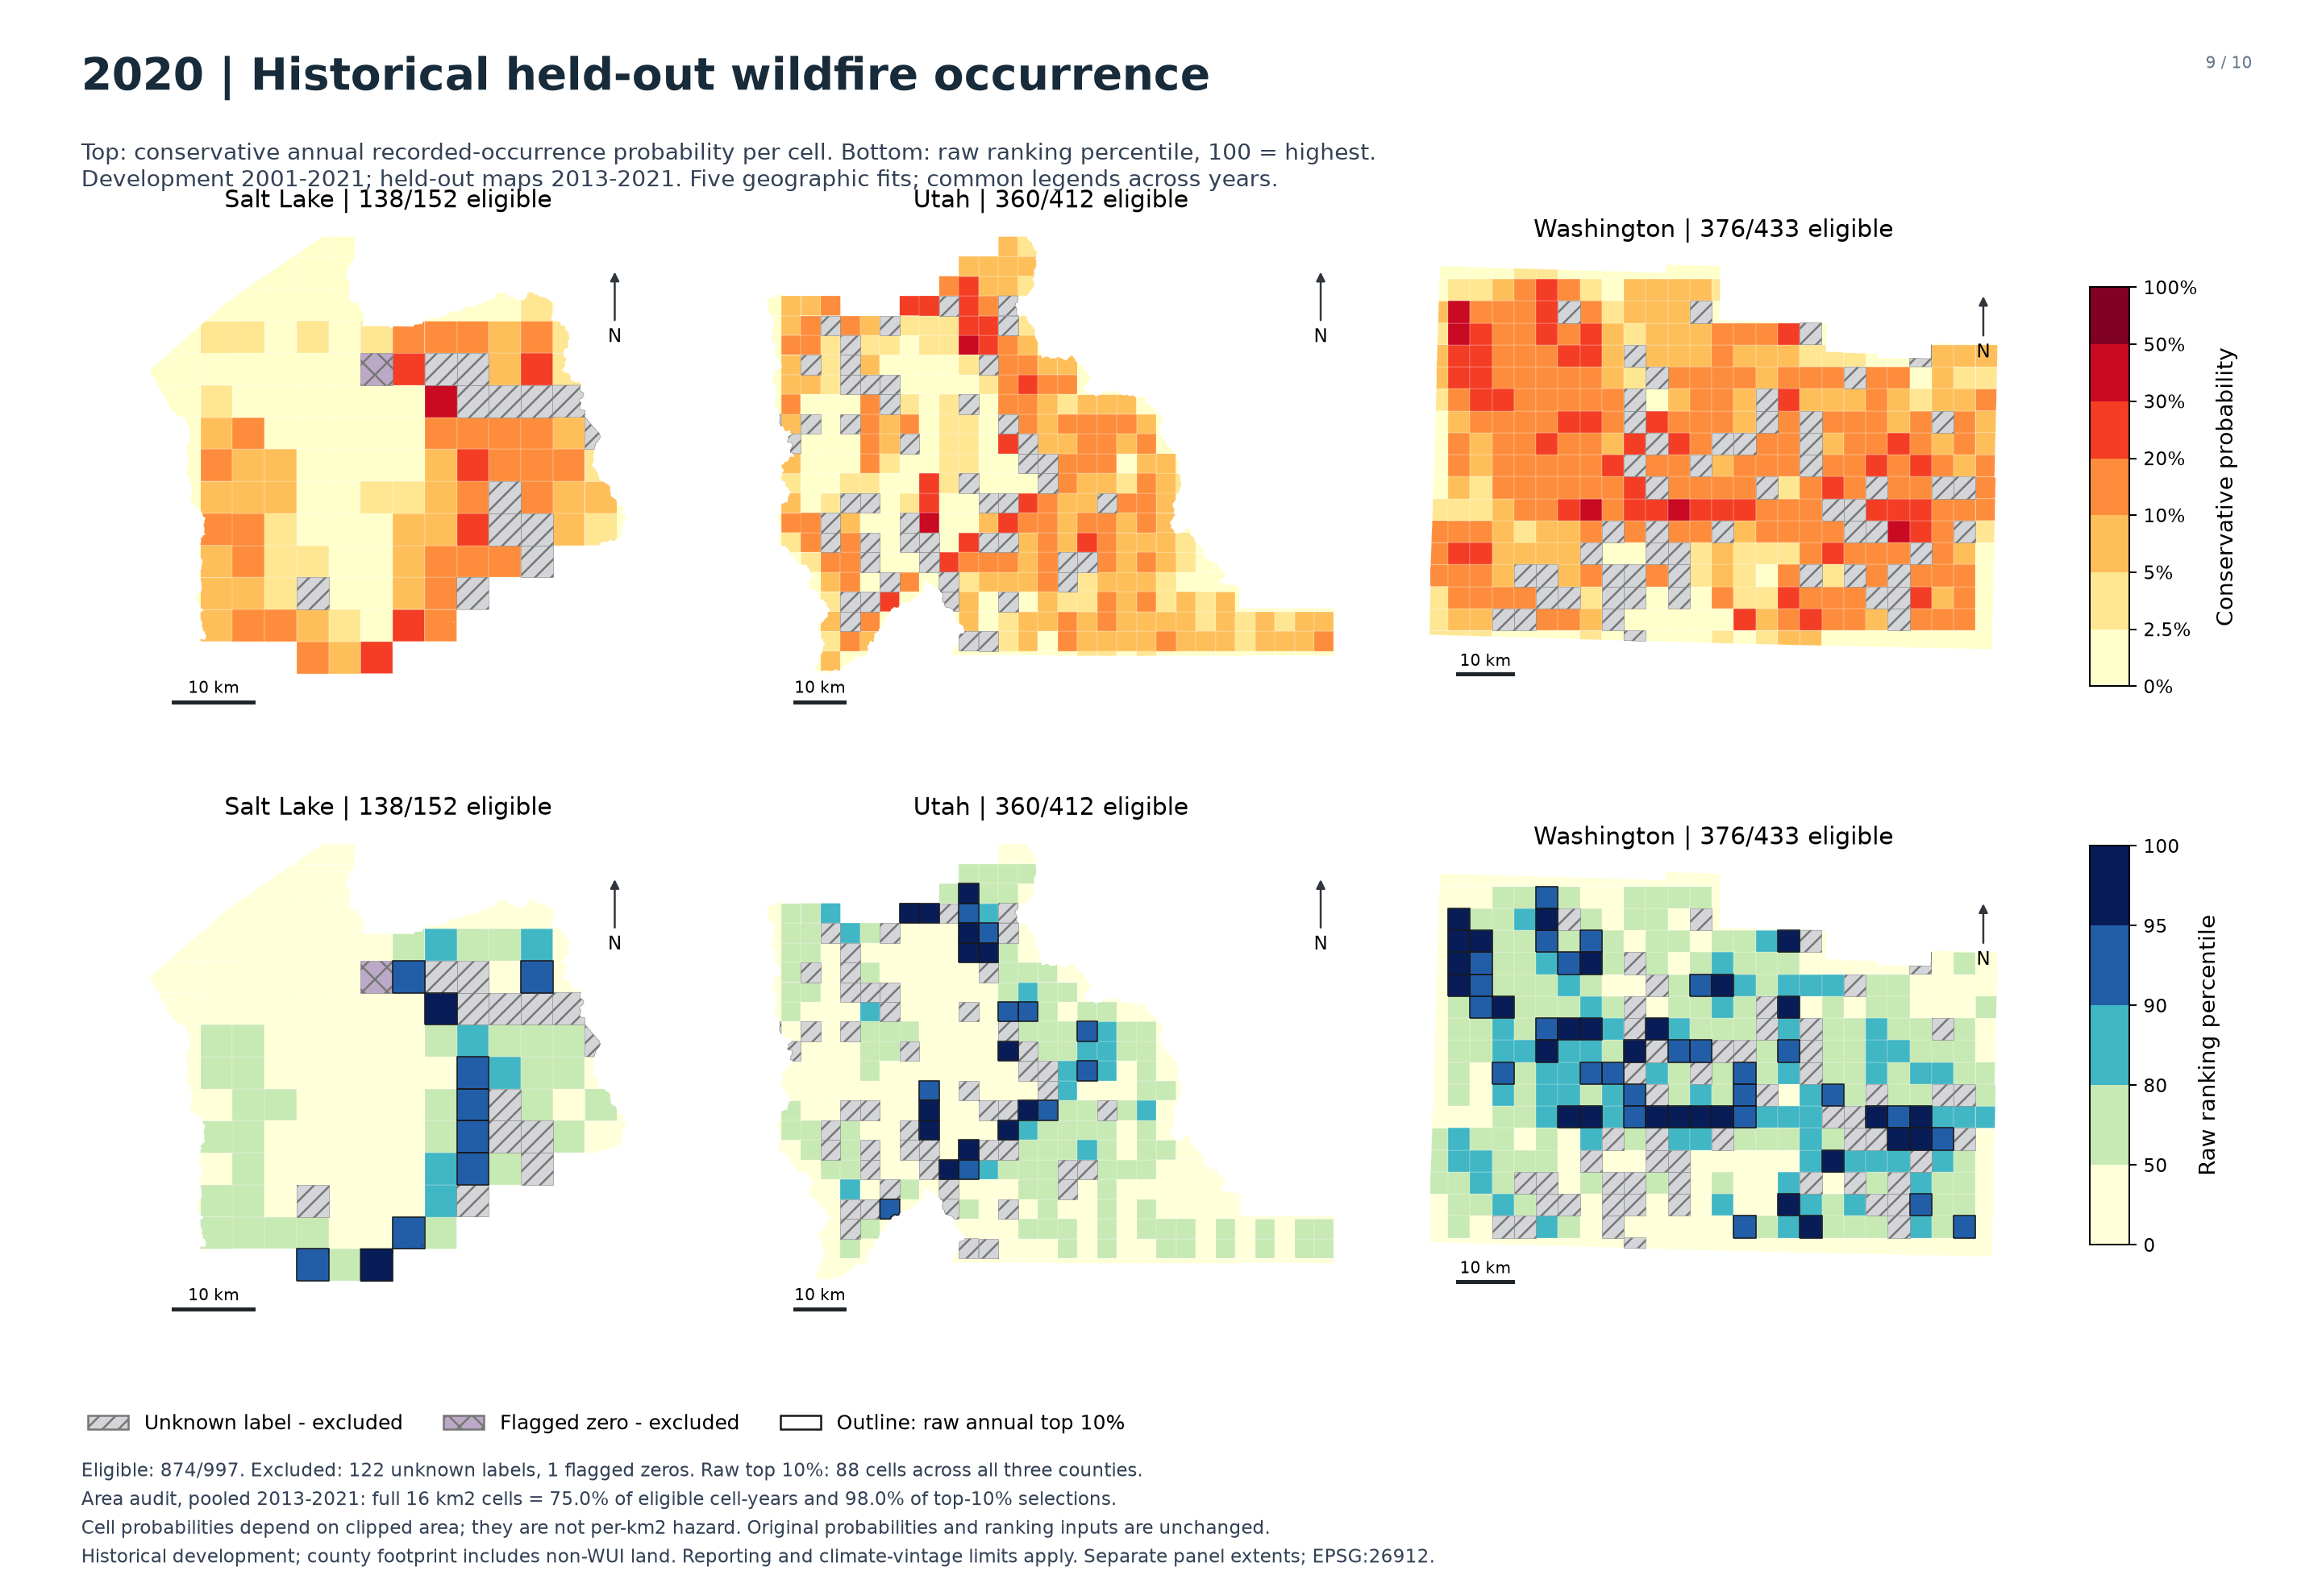

2020: 874 of 997 original cells have held-out predictions; 122 unknown-label and 1 flagged-zero cells are excluded. Outlines select 88 cells across the three-county cohort. In this year, full cells represent 73.5% of eligible cells and 98.9% of raw top-decile selections. Upper panels show conservative probabilities; lower panels show raw ranking percentiles. Original-area values are retained, and boundary-cell probabilities are not per-km² hazard measures. Development years informed model selection; terrain is a contemporary static proxy.

Geographic comparison among eligible cells: Salt Lake has mean conservative probability 6.17% and 10 raw top-decile cells; Utah has mean conservative probability 6.69% and 23 raw top-decile cells; Washington has mean conservative probability 11.12% and 55 raw top-decile cells. County averages do not imply uniform conditions within a county; the mapped pattern is clustered, and panel scales differ.

In [10]:
item = maps[7]
display(Markdown("## 2020 development holdout"))
display(Image(filename=str(ROOT / item["image"]), width=1100))
display(Markdown(item["caption"] + "\n\n" + item["spatial_description"]))

## 2021 development holdout

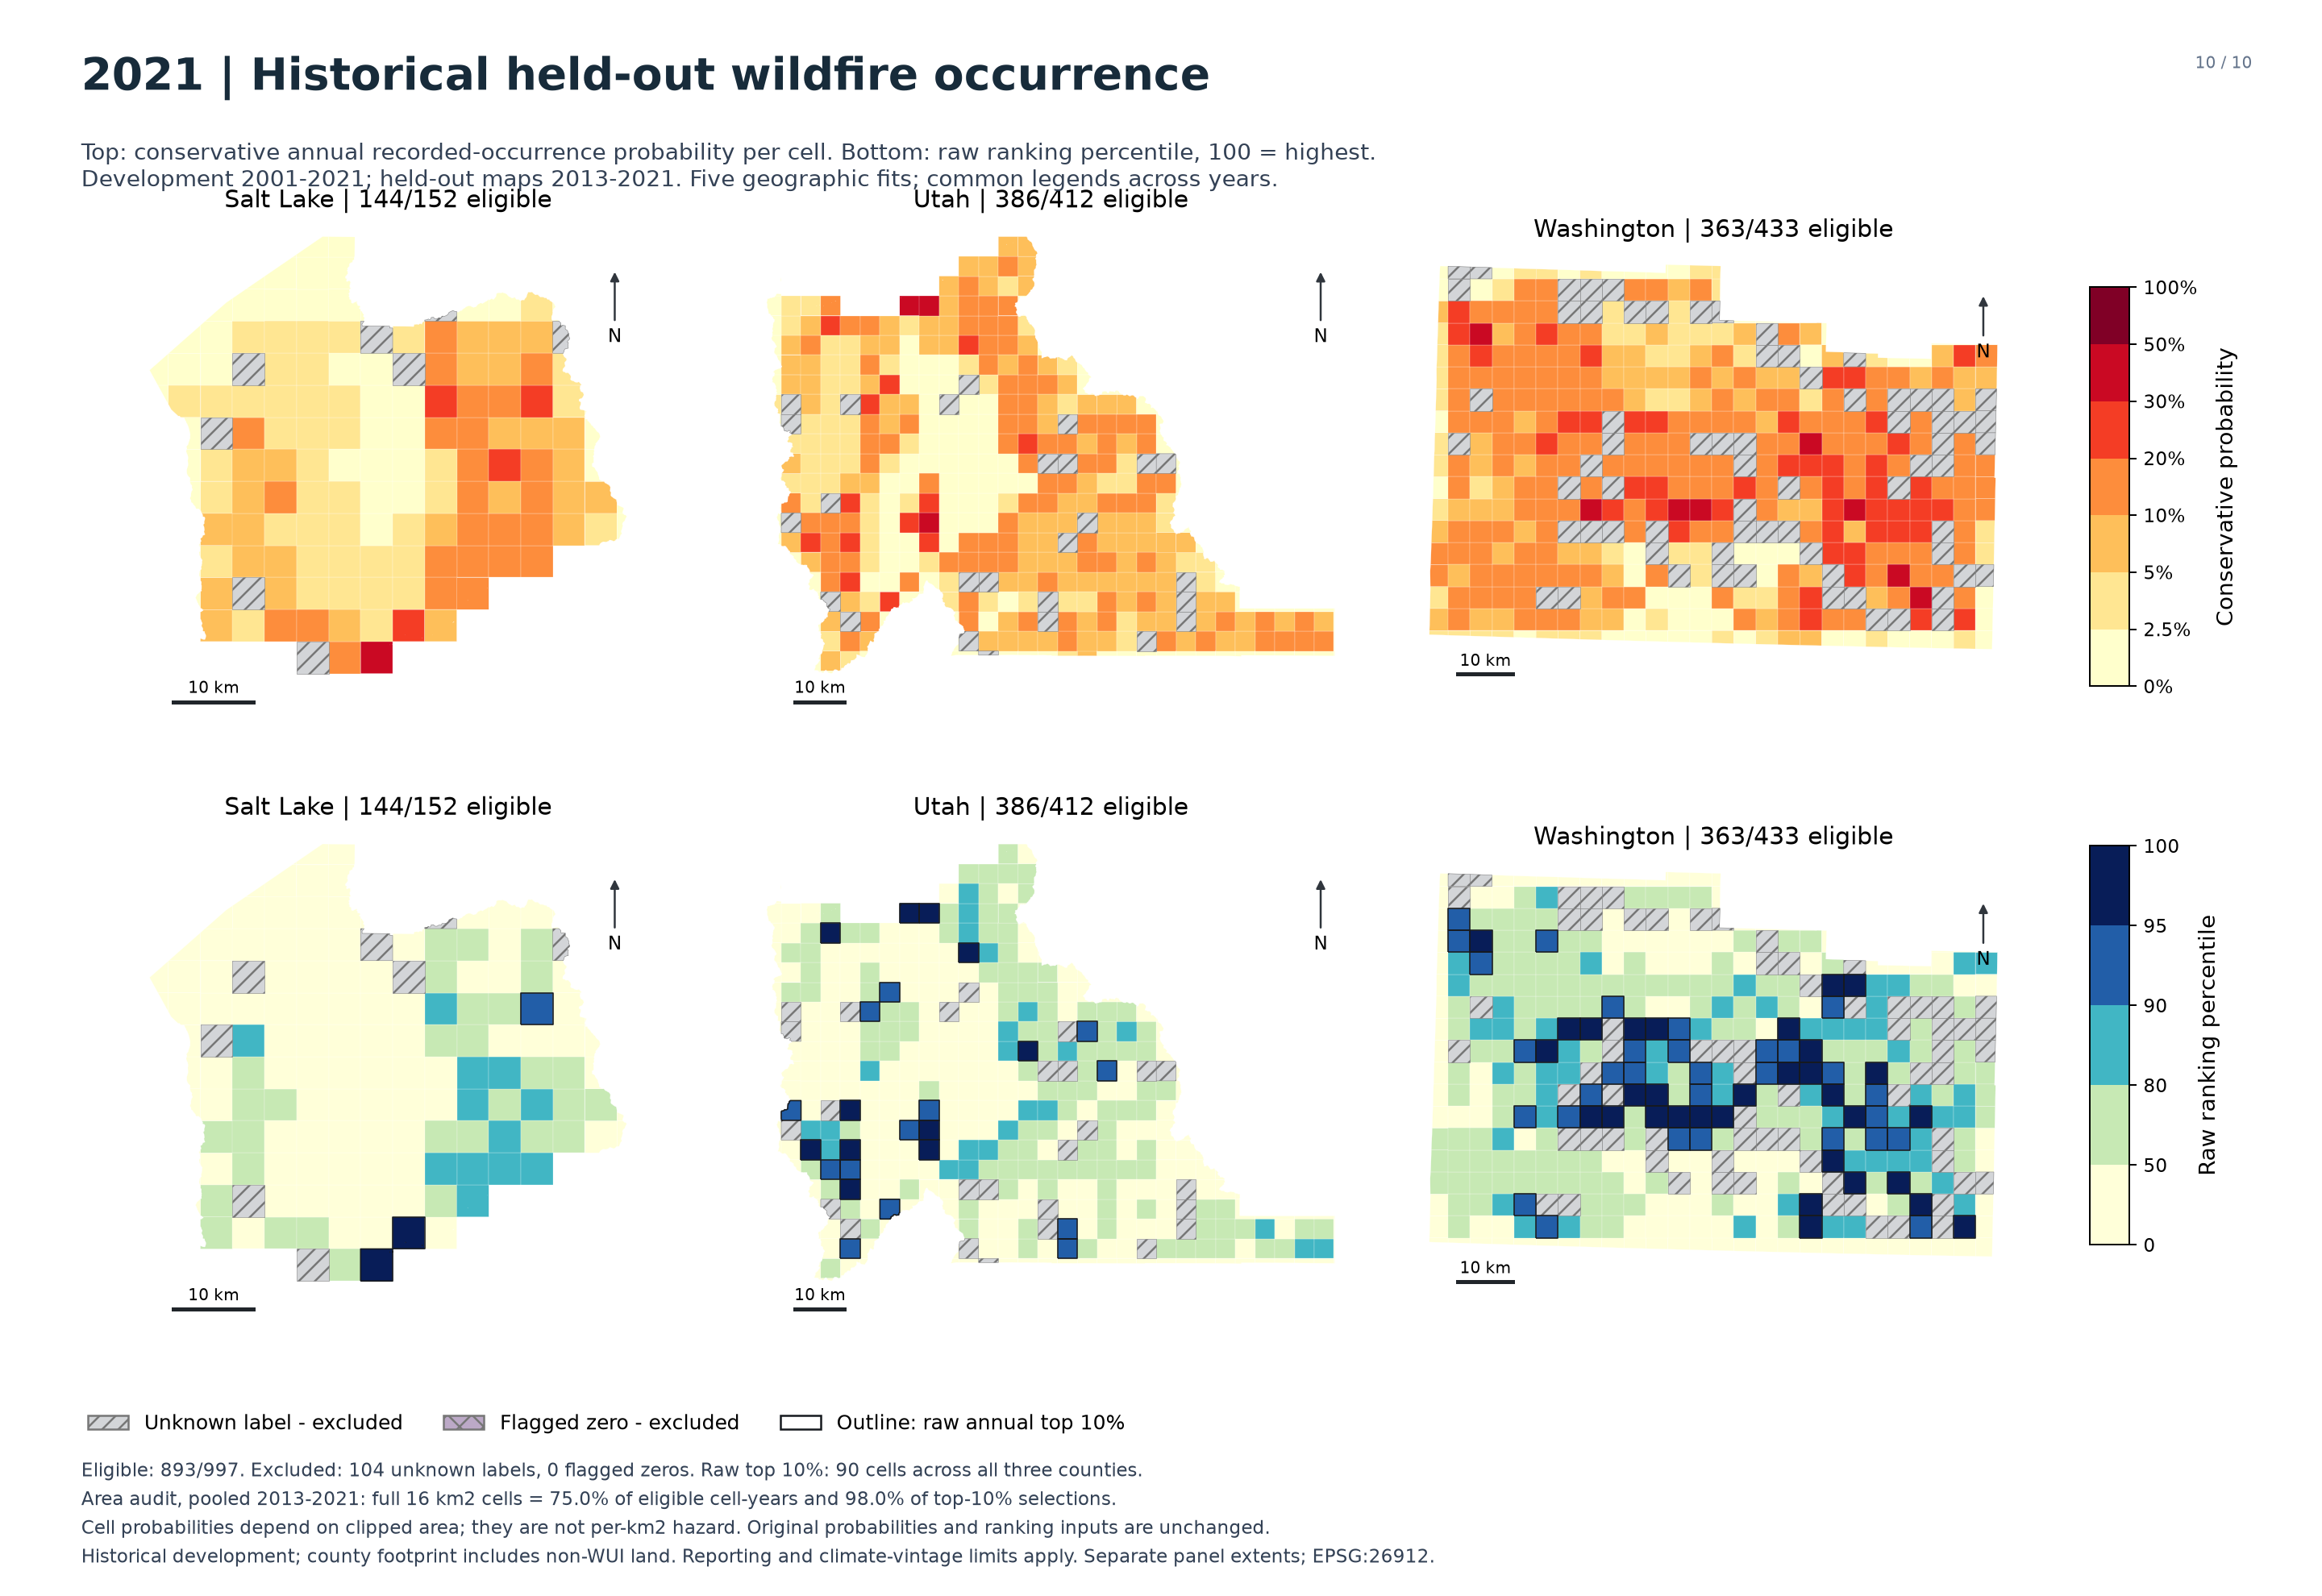

2021: 893 of 997 original cells have held-out predictions; 104 unknown-label and 0 flagged-zero cells are excluded. Outlines select 90 cells across the three-county cohort. In this year, full cells represent 74.7% of eligible cells and 97.8% of raw top-decile selections. Upper panels show conservative probabilities; lower panels show raw ranking percentiles. Original-area values are retained, and boundary-cell probabilities are not per-km² hazard measures. Development years informed model selection; terrain is a contemporary static proxy.

Geographic comparison among eligible cells: Salt Lake has mean conservative probability 5.93% and 3 raw top-decile cells; Utah has mean conservative probability 7.15% and 24 raw top-decile cells; Washington has mean conservative probability 11.70% and 63 raw top-decile cells. County averages do not imply uniform conditions within a county; the mapped pattern is clustered, and panel scales differ.

In [11]:
item = maps[8]
display(Markdown("## 2021 development holdout"))
display(Image(filename=str(ROOT / item["image"]), width=1100))
display(Markdown(item["caption"] + "\n\n" + item["spatial_description"]))